In [236]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import os

from sklearn.preprocessing import LabelEncoder, StandardScaler, label_binarize
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score, roc_curve, classification_report
)
from scipy import stats


In [237]:
DATA_DIR         = '/home/arrizam/Desktop/Acad 3-2/MLPROJ/'  # change if needed
def load_csv(filename):
    df = pd.read_csv(filename, on_bad_lines='skip', low_memory=False)
    print(f'  {filename:<40} {df.shape[0]:>7} rows  {df.shape[1]:>3} cols')
    return df

allergies         = load_csv('allergies.csv')
careplans         = load_csv('careplans.csv')
claims            = load_csv('claims.csv')
conditions        = load_csv('conditions.csv')
devices           = load_csv('devices.csv')
encounters        = load_csv('encounters.csv')
imaging_studies   = load_csv('imaging_studies.csv')
immunizations     = load_csv('immunizations.csv')
medications       = load_csv('medications.csv')
observations      = load_csv('observations.csv')
organizations     = load_csv('organizations.csv')
patients          = load_csv('patients.csv')
payer_transitions = load_csv('payer_transitions.csv')
procedures        = load_csv('procedures.csv')
providers         = load_csv('providers.csv')
supplies          = load_csv('supplies.csv')
print('\nDone.')

  allergies.csv                               2500 rows   15 cols
  careplans.csv                               8166 rows    9 cols
  claims.csv                                228088 rows   31 cols
  conditions.csv                              3238 rows   11 cols
  devices.csv                                12164 rows    7 cols
  encounters.csv                            126048 rows   15 cols
  imaging_studies.csv                       193869 rows   13 cols
  immunizations.csv                          32412 rows    6 cols
  medications.csv                           102402 rows   13 cols
  observations.csv                         1535041 rows    9 cols
  organizations.csv                              3 rows   11 cols
  patients.csv                                2823 rows   28 cols
  payer_transitions.csv                      80543 rows    8 cols
  procedures.csv                            343112 rows   10 cols
  providers.csv                                  2 rows   13 cols
  supplies

In [238]:
allergies.columns

Index(['START', 'STOP', 'PATIENT', 'ENCOUNTER', 'CODE', 'SYSTEM',
       'DESCRIPTION', 'TYPE', 'CATEGORY', 'REACTION1', 'DESCRIPTION1',
       'SEVERITY1', 'REACTION2', 'DESCRIPTION2', 'SEVERITY2'],
      dtype='object')

In [239]:
careplans.columns

Index(['Id', 'START', 'STOP', 'PATIENT', 'ENCOUNTER', 'CODE', 'DESCRIPTION',
       'REASONCODE', 'REASONDESCRIPTION'],
      dtype='object')

In [240]:
claims.columns

Index(['Id', 'PATIENTID', 'PROVIDERID', 'PRIMARYPATIENTINSURANCEID',
       'SECONDARYPATIENTINSURANCEID', 'DEPARTMENTID', 'PATIENTDEPARTMENTID',
       'DIAGNOSIS1', 'DIAGNOSIS2', 'DIAGNOSIS3', 'DIAGNOSIS4', 'DIAGNOSIS5',
       'DIAGNOSIS6', 'DIAGNOSIS7', 'DIAGNOSIS8', 'REFERRINGPROVIDERID',
       'APPOINTMENTID', 'CURRENTILLNESSDATE', 'SERVICEDATE',
       'SUPERVISINGPROVIDERID', 'STATUS1', 'STATUS2', 'STATUSP',
       'OUTSTANDING1', 'OUTSTANDING2', 'OUTSTANDINGP', 'LASTBILLEDDATE1',
       'LASTBILLEDDATE2', 'LASTBILLEDDATEP', 'HEALTHCARECLAIMTYPEID1',
       'HEALTHCARECLAIMTYPEID2'],
      dtype='object')

In [241]:
conditions.columns

Index(['START', 'STOP', 'PATIENT', 'ENCOUNTER', 'SYSTEM', 'CODE',
       'DESCRIPTION', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10'],
      dtype='object')

In [242]:
devices.columns

Index(['START', 'STOP', 'PATIENT', 'ENCOUNTER', 'CODE', 'DESCRIPTION', 'UDI'], dtype='object')

In [243]:
encounters.columns

Index(['Id', 'START', 'STOP', 'PATIENT', 'ORGANIZATION', 'PROVIDER', 'PAYER',
       'ENCOUNTERCLASS', 'CODE', 'DESCRIPTION', 'BASE_ENCOUNTER_COST',
       'TOTAL_CLAIM_COST', 'PAYER_COVERAGE', 'REASONCODE',
       'REASONDESCRIPTION'],
      dtype='object')

In [244]:
imaging_studies.columns

Index(['Id', 'DATE', 'PATIENT', 'ENCOUNTER', 'SERIES_UID', 'BODYSITE_CODE',
       'BODYSITE_DESCRIPTION', 'MODALITY_CODE', 'MODALITY_DESCRIPTION',
       'INSTANCE_UID', 'SOP_CODE', 'SOP_DESCRIPTION', 'PROCEDURE_CODE'],
      dtype='object')

In [245]:
immunizations.columns

Index(['DATE', 'PATIENT', 'ENCOUNTER', 'CODE', 'DESCRIPTION', 'BASE_COST'], dtype='object')

In [246]:
medications.columns

Index(['START', 'STOP', 'PATIENT', 'PAYER', 'ENCOUNTER', 'CODE', 'DESCRIPTION',
       'BASE_COST', 'PAYER_COVERAGE', 'DISPENSES', 'TOTALCOST', 'REASONCODE',
       'REASONDESCRIPTION'],
      dtype='object')

In [247]:
observations.columns

Index(['DATE', 'PATIENT', 'ENCOUNTER', 'CATEGORY', 'CODE', 'DESCRIPTION',
       'VALUE', 'UNITS', 'TYPE'],
      dtype='object')

In [248]:
organizations.columns

Index(['Id', 'NAME', 'ADDRESS', 'CITY', 'STATE', 'ZIP', 'LAT', 'LON', 'PHONE',
       'REVENUE', 'UTILIZATION'],
      dtype='object')

In [249]:
patients.columns

Index(['Id', 'BIRTHDATE', 'DEATHDATE', 'SSN', 'DRIVERS', 'PASSPORT', 'PREFIX',
       'FIRST', 'MIDDLE', 'LAST', 'SUFFIX', 'MAIDEN', 'MARITAL', 'RACE',
       'ETHNICITY', 'GENDER', 'BIRTHPLACE', 'ADDRESS', 'CITY', 'STATE',
       'COUNTY', 'FIPS', 'ZIP', 'LAT', 'LON', 'HEALTHCARE_EXPENSES',
       'HEALTHCARE_COVERAGE', 'INCOME'],
      dtype='object')

In [250]:
payer_transitions.columns

Index(['PATIENT', 'MEMBERID', 'START_DATE', 'END_DATE', 'PAYER',
       'SECONDARY_PAYER', 'PLAN_OWNERSHIP', 'OWNER_NAME'],
      dtype='object')

In [251]:
procedures.columns

Index(['START', 'STOP', 'PATIENT', 'ENCOUNTER', 'SYSTEM', 'CODE',
       'DESCRIPTION', 'BASE_COST', 'REASONCODE', 'REASONDESCRIPTION'],
      dtype='object')

In [252]:
providers.columns

Index(['Id', 'ORGANIZATION', 'NAME', 'GENDER', 'SPECIALITY', 'ADDRESS', 'CITY',
       'STATE', 'ZIP', 'LAT', 'LON', 'ENCOUNTERS', 'PROCEDURES'],
      dtype='object')

In [253]:
supplies.columns

Index(['DATE', 'PATIENT', 'ENCOUNTER', 'CODE', 'DESCRIPTION', 'QUANTITY'], dtype='object')

In [254]:
date_cols = {
    'patients':['BIRTHDATE'],
    'encounters':['START','STOP'],
    'conditions':['START','STOP'],
    'observations':['DATE'],
    'medications':['START','STOP']
}

for col in ['START','STOP']:
    if col in encounters:
        encounters[col]=pd.to_datetime(encounters[col])

In [255]:
enc_features=(
encounters
.groupby('PATIENT')
.agg(
    num_encounters=('Id','count'),
    mean_encounter_cost=('BASE_ENCOUNTER_COST','mean'),
    total_claim_cost=('TOTAL_CLAIM_COST','sum'),
    avg_payer_coverage=('PAYER_COVERAGE','mean')
)
.reset_index()
)

In [256]:
cond_features=(
conditions
.groupby('PATIENT')
.agg(
    num_conditions=('CODE','count'),
    unique_conditions=('CODE','nunique')
)
.reset_index()
)

In [257]:
med_features=(
medications
.groupby('PATIENT')
.agg(
    medication_count=('CODE','count'),
    medication_cost=('TOTALCOST','sum')
)
.reset_index()
)

In [258]:
master = patients.copy()

for df in [enc_features, cond_features, med_features]:
    master = master.merge(
        df,
        left_on='Id',
        right_on='PATIENT',
        how='left'
    )


master.drop(columns=['PATIENT_x', 'PATIENT_y', 'PATIENT'], errors='ignore', inplace=True)

master.fillna(0, inplace=True)

In [259]:
last_encounter = (
encounters.groupby('PATIENT')['START']
.max()
.reset_index(name='LAST_ENCOUNTER')
)

master = master.merge(
last_encounter,
left_on='Id',
right_on='PATIENT',
how='left'
)

In [260]:
master.columns

Index(['Id', 'BIRTHDATE', 'DEATHDATE', 'SSN', 'DRIVERS', 'PASSPORT', 'PREFIX',
       'FIRST', 'MIDDLE', 'LAST', 'SUFFIX', 'MAIDEN', 'MARITAL', 'RACE',
       'ETHNICITY', 'GENDER', 'BIRTHPLACE', 'ADDRESS', 'CITY', 'STATE',
       'COUNTY', 'FIPS', 'ZIP', 'LAT', 'LON', 'HEALTHCARE_EXPENSES',
       'HEALTHCARE_COVERAGE', 'INCOME', 'num_encounters',
       'mean_encounter_cost', 'total_claim_cost', 'avg_payer_coverage',
       'num_conditions', 'unique_conditions', 'medication_count',
       'medication_cost', 'PATIENT', 'LAST_ENCOUNTER'],
      dtype='object')

In [261]:
master = master.drop(columns=['PATIENT'], errors='ignore')

In [262]:
import pandas as pd
import numpy as np

master['BIRTHDATE'] = pd.to_datetime(master['BIRTHDATE'])
master['DEATHDATE'] = pd.to_datetime(
    master['DEATHDATE'],
    errors='coerce'
)

reference_date = pd.Timestamp.today().normalize()

age_date = master['DEATHDATE'].fillna(reference_date)

master['AGE'] = (
    (age_date-master['BIRTHDATE']).dt.days/365.25
).astype(int)

master['DECEASED'] = (
    master['DEATHDATE'].notna()
).astype(int)

In [263]:
enc_class = pd.crosstab(
    encounters['PATIENT'],
    encounters['ENCOUNTERCLASS']
).reset_index()

enc_class.columns = [
    'Id' if c=='PATIENT'
    else f'enc_{c}_count'
    for c in enc_class.columns
]

master = master.merge(
    enc_class,
    on='Id',
    how='left'
)

In [264]:
master['LAST_ENCOUNTER'] = pd.to_datetime(master['LAST_ENCOUNTER'])

ref_date = master['LAST_ENCOUNTER'].max()

master['days_since_last_enc'] = (
    ref_date-master['LAST_ENCOUNTER']
).dt.days

In [265]:
master['enc_frequency_per_year'] = (
master['num_encounters']/
(master['AGE']+1)
)

In [266]:
conditions['STOP']=pd.to_datetime(
conditions['STOP'],
errors='coerce'
)

conditions['active_cond']=(
conditions['STOP'].isna()
).astype(int)

cond_active=(
conditions.groupby('PATIENT')['active_cond']
.sum()
.reset_index()
.rename(
columns={
'PATIENT':'Id',
'active_cond':'condition_active_count'
}
)
)

master=master.merge(
cond_active,
on='Id',
how='left'
)

/tmp/ipykernel_95984/1079970080.py:1: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  conditions['STOP']=pd.to_datetime(


In [267]:
medications['STOP']=pd.to_datetime(
medications['STOP'],
errors='coerce'
)

medications['active_med']=(
medications['STOP'].isna()
).astype(int)

med_features2=(
medications.groupby('PATIENT')
.agg(
med_unique=('CODE','nunique'),
med_active_count=('active_med','sum'),
med_dispenses=('DISPENSES','sum')
)
.reset_index()
.rename(columns={'PATIENT':'Id'})
)

master=master.merge(
med_features2,
on='Id',
how='left'
)

In [268]:
proc_features=(
procedures.groupby('PATIENT')
.agg(
proc_count=('CODE','count'),
proc_cost_sum=('BASE_COST','sum'),
proc_cost_mean=('BASE_COST','mean'),
proc_cost_var=('BASE_COST','var')
)
.reset_index()
.rename(columns={'PATIENT':'Id'})
)

master=master.merge(
proc_features,
on='Id',
how='left'
)

In [269]:
observations['DATE']=pd.to_datetime(
observations['DATE']
)

observations['VALUE']=pd.to_numeric(
observations['VALUE'],
errors='coerce'
)

In [270]:
targets={
'Body mass index':'bmi',
'Systolic Blood Pressure':'systolic_bp',
'Diastolic Blood Pressure':'diastolic_bp',
'Body Weight':'weight',
'Glucose':'glucose'
}

In [271]:
for label,short in targets.items():

    temp=observations[
        observations['DESCRIPTION']
        .str.contains(
            label,
            case=False,
            na=False
        )
    ].copy()

    agg=(
    temp.groupby('PATIENT')['VALUE']
    .agg(
        ['mean','var']
    )
    .reset_index()
    )

    agg.columns=[
        'Id',
        f'obs_{short}_mean',
        f'obs_{short}_var'
    ]

    latest=(
    temp.sort_values('DATE')
    .groupby('PATIENT')
    .tail(1)[['PATIENT','VALUE']]
    .rename(
        columns={
        'PATIENT':'Id',
        'VALUE':f'obs_{short}_latest'
        }
    )
    )

    feat=agg.merge(
        latest,
        on='Id',
        how='outer'
    )

    master=master.merge(
        feat,
        on='Id',
        how='left'
    )

In [272]:
master['cost_per_encounter']=(
master['total_claim_cost']/
(master['num_encounters']+1)
)

master['condition_per_encounter']=(
master['num_conditions']/
(master['num_encounters']+1)
)

master['polypharmacy']=(
master['medication_count']>=5
).astype(int)

master['expense_income_ratio']=(
master['HEALTHCARE_EXPENSES']/
(master['INCOME']+1)
)

In [273]:
master.isna().sum().sort_values(ascending=False)

condition_active_count    2715
DEATHDATE                 2454
obs_glucose_var           1789
obs_glucose_latest        1686
obs_glucose_mean          1647
                          ... 
HEALTHCARE_EXPENSES          0
LON                          0
LAT                          0
ZIP                          0
expense_income_ratio         0
Length: 78, dtype: int64

In [274]:
master.fillna(0,inplace=True)

/tmp/ipykernel_95984/2783242028.py:1: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '0' has dtype incompatible with datetime64[ns, UTC], please explicitly cast to a compatible dtype first.
  master.fillna(0,inplace=True)
/tmp/ipykernel_95984/2783242028.py:1: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '0' has dtype incompatible with datetime64[ns], please explicitly cast to a compatible dtype first.
  master.fillna(0,inplace=True)


In [275]:
master.head()

,Id,BIRTHDATE,DEATHDATE,SSN,DRIVERS,PASSPORT,PREFIX,FIRST,MIDDLE,LAST,...,obs_weight_mean,obs_weight_var,obs_weight_latest,obs_glucose_mean,obs_glucose_var,obs_glucose_latest,cost_per_encounter,condition_per_encounter,polypharmacy,expense_income_ratio
0,0f238ca9-106f-4cd6-d8d1-701e70c84cb6,2001-01-10,2001-09-21 00:00:00,999-65-9711,0,0,0,Eldridge510,0,Murphy561,...,6.400000,3.106667,8.5,0.0,0.0,0.0,2487.167500,0.750000,0,0.476644
1,a35facb9-a2fd-363c-dc7f-5f32ed850c45,1971-03-31,1983-06-17 00:00:00,999-17-4477,0,0,0,Fransisca150,0,Tillman293,...,28.566667,177.840606,55.5,0.0,0.0,0.0,2149.828462,0.423077,1,1.050880
2,e3e20559-00f1-a5b1-0e26-4145235cccbf,2016-09-06,0,999-24-6886,0,0,0,Indira327,Stefany238,Moen819,...,14.045000,48.411026,27.3,0.0,0.0,0.0,1016.156486,0.567568,1,0.202416
3,90f0bc22-78e9-3b0c-0479-e2d5091cba18,2003-09-18,0,999-23-7519,S99954943,X74471475X,Mr.,Carmen818,0,Hilpert278,...,63.490000,33.347667,71.2,0.0,0.0,0.0,1377.451111,0.888889,1,2.007735
4,f9b654e0-f9bd-b806-5e72-fbe4a7463c94,2006-08-10,0,999-77-6032,S99954224,0,Mr.,Kelley882,0,Lind531,...,64.300000,441.906667,85.6,0.0,0.0,0.0,1289.578182,0.909091,1,0.390740


In [276]:
master.columns

Index(['Id', 'BIRTHDATE', 'DEATHDATE', 'SSN', 'DRIVERS', 'PASSPORT', 'PREFIX',
       'FIRST', 'MIDDLE', 'LAST', 'SUFFIX', 'MAIDEN', 'MARITAL', 'RACE',
       'ETHNICITY', 'GENDER', 'BIRTHPLACE', 'ADDRESS', 'CITY', 'STATE',
       'COUNTY', 'FIPS', 'ZIP', 'LAT', 'LON', 'HEALTHCARE_EXPENSES',
       'HEALTHCARE_COVERAGE', 'INCOME', 'num_encounters',
       'mean_encounter_cost', 'total_claim_cost', 'avg_payer_coverage',
       'num_conditions', 'unique_conditions', 'medication_count',
       'medication_cost', 'LAST_ENCOUNTER', 'AGE', 'DECEASED',
       'enc_ambulatory_count', 'enc_emergency_count', 'enc_home_count',
       'enc_hospice_count', 'enc_inpatient_count', 'enc_outpatient_count',
       'enc_snf_count', 'enc_urgentcare_count', 'enc_virtual_count',
       'enc_wellness_count', 'days_since_last_enc', 'enc_frequency_per_year',
       'condition_active_count', 'med_unique', 'med_active_count',
       'med_dispenses', 'proc_count', 'proc_cost_sum', 'proc_cost_mean',
       'proc_c

In [277]:
drop_cols = [
'Id',
'SSN',
'DRIVERS',
'PASSPORT',
'FIRST',
'MIDDLE',
'LAST',
'SUFFIX',
'MAIDEN',
'ADDRESS',
'ZIP',
'LAT',
'LON',
'FIPS'
]

master.drop(columns=drop_cols,inplace=True)

In [278]:
master.columns

Index(['BIRTHDATE', 'DEATHDATE', 'PREFIX', 'MARITAL', 'RACE', 'ETHNICITY',
       'GENDER', 'BIRTHPLACE', 'CITY', 'STATE', 'COUNTY',
       'HEALTHCARE_EXPENSES', 'HEALTHCARE_COVERAGE', 'INCOME',
       'num_encounters', 'mean_encounter_cost', 'total_claim_cost',
       'avg_payer_coverage', 'num_conditions', 'unique_conditions',
       'medication_count', 'medication_cost', 'LAST_ENCOUNTER', 'AGE',
       'DECEASED', 'enc_ambulatory_count', 'enc_emergency_count',
       'enc_home_count', 'enc_hospice_count', 'enc_inpatient_count',
       'enc_outpatient_count', 'enc_snf_count', 'enc_urgentcare_count',
       'enc_virtual_count', 'enc_wellness_count', 'days_since_last_enc',
       'enc_frequency_per_year', 'condition_active_count', 'med_unique',
       'med_active_count', 'med_dispenses', 'proc_count', 'proc_cost_sum',
       'proc_cost_mean', 'proc_cost_var', 'obs_bmi_mean', 'obs_bmi_var',
       'obs_bmi_latest', 'obs_systolic_bp_mean', 'obs_systolic_bp_var',
       'obs_systolic_bp_

In [279]:
master['pulse_pressure']=(
master['obs_systolic_bp_latest']
-
master['obs_diastolic_bp_latest']
)



In [280]:
threshold = master['pulse_pressure'].quantile(0.75)

master['pulse_flag'] = (
    master['pulse_pressure'] >= threshold
).astype(int)

In [281]:
master['obese_flag']=(
master['obs_bmi_latest']>=30
).astype(int)

In [282]:
master_eda = master.copy()

In [283]:
cat_cols = [
'MARITAL',
'RACE',
'ETHNICITY',
'GENDER',
'CITY',
'STATE'
]

master = pd.get_dummies(
    master,
    columns=cat_cols,
    drop_first=True
)

**TEMPORAL SPLIT**

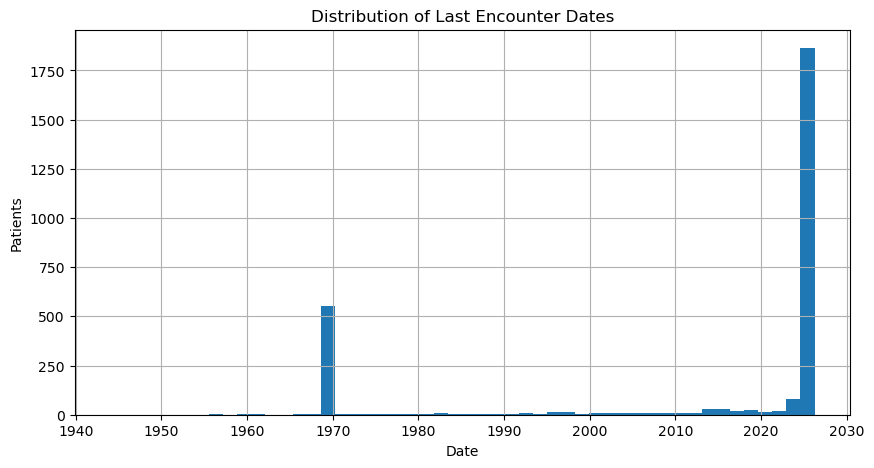

0


In [284]:

import matplotlib.pyplot as plt

master['LAST_ENCOUNTER'] = pd.to_datetime(
    master['LAST_ENCOUNTER'],
    errors='coerce',
    utc=True
).dt.tz_localize(None)

plt.figure(figsize=(10,5))
master['LAST_ENCOUNTER'].hist(bins=50)

plt.title('Distribution of Last Encounter Dates')
plt.xlabel('Date')
plt.ylabel('Patients')
plt.show()

print(master['LAST_ENCOUNTER'].isna().sum())

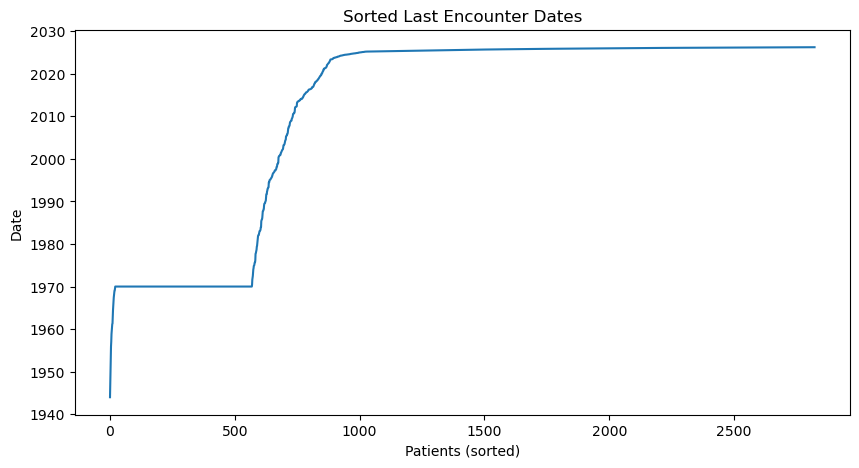

In [285]:
dates_sorted = master['LAST_ENCOUNTER'].sort_values().reset_index(drop=True)

plt.figure(figsize=(10,5))
plt.plot(dates_sorted)

plt.title('Sorted Last Encounter Dates')
plt.ylabel('Date')
plt.xlabel('Patients (sorted)')
plt.show()

Due to large spike in the 1970s and 2020s 1st Jan 2000 was chosen as a cutoff.
Reason for choosing LAST_ENCOUNTER person may be born in 1980s but medical records in 2010s so has to classified as current.

In [286]:

historical = master[
master['LAST_ENCOUNTER'] < '2000-01-01'
]

current = master[
master['LAST_ENCOUNTER'] >= '2000-01-01'
]

In [287]:

master_eda['LAST_ENCOUNTER'] = pd.to_datetime(
    master_eda['LAST_ENCOUNTER'],
    utc=True
)

In [288]:
historical_eda = master_eda[
master['LAST_ENCOUNTER'] < '2000-01-01'
]

current_eda = master_eda[
master['LAST_ENCOUNTER'] >= '2000-01-01'
]

In [289]:
historical_eda.columns
current_eda.columns

historical.columns
current.columns

Index(['BIRTHDATE', 'DEATHDATE', 'PREFIX', 'BIRTHPLACE', 'COUNTY',
       'HEALTHCARE_EXPENSES', 'HEALTHCARE_COVERAGE', 'INCOME',
       'num_encounters', 'mean_encounter_cost',
       ...
       'CITY_Winchendon', 'CITY_Winchester', 'CITY_Winthrop', 'CITY_Woburn',
       'CITY_Woods Hole', 'CITY_Worcester', 'CITY_Worthington',
       'CITY_Wrentham', 'CITY_Yarmouth', 'CITY_Yarmouth Port'],
      dtype='object', length=409)

In [290]:
print(historical_eda.shape, current_eda.shape)
print(historical_eda['LAST_ENCOUNTER'].min(), current_eda['LAST_ENCOUNTER'].min())

(675, 67) (2148, 67)
1943-12-30 02:05:12+00:00 2000-05-18 16:50:44+00:00


In [291]:
print(historical.shape, current_eda.shape)
print(historical['LAST_ENCOUNTER'].min(), current_eda['LAST_ENCOUNTER'].min())

(675, 409) (2148, 67)
1943-12-30 02:05:12 2000-05-18 16:50:44+00:00


**EDA**

In [292]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def run_eda(df, name="Dataset"):
    print(f"\n===== {name} EDA =====\n")


    print("Shape:", df.shape)
    print("\nMissing Values:\n", df.isnull().sum().sort_values(ascending=False).head(10))

    print("\nSummary Statistics:\n", df.describe())

    cat_cols = df.select_dtypes(include='object').columns
    print("\nCategorical Columns:", cat_cols)

    for col in cat_cols:
        print(f"\nValue counts for {col}:")
        print(df[col].value_counts(normalize=True).head())

  
    num_cols = df.select_dtypes(include=['int64','float64']).columns

  
    plt.figure(figsize=(12,8))
    corr = df[num_cols].corr()
    sns.heatmap(corr, cmap='coolwarm')
    plt.title(f"{name} Correlation Heatmap")
    plt.show()

 
    key_cols = [
        'AGE', 'total_claim_cost', 'num_encounters',
        'num_conditions', 'medication_count'
    ]

    for col in key_cols:
        if col in df.columns:
            plt.figure()
            sns.histplot(df[col], kde=True)
            plt.title(f"{name} - Distribution of {col}")
            plt.show()

    for col in key_cols:
        if col in df.columns:
            plt.figure()
            sns.boxplot(x=df[col])
            plt.title(f"{name} - Boxplot of {col}")
            plt.show()


===== Historical Data EDA =====

Shape: (675, 67)

Missing Values:
 BIRTHDATE                 0
obs_systolic_bp_latest    0
enc_frequency_per_year    0
condition_active_count    0
med_unique                0
med_active_count          0
med_dispenses             0
proc_count                0
proc_cost_sum             0
proc_cost_mean            0
dtype: int64

Summary Statistics:
                  BIRTHDATE  HEALTHCARE_EXPENSES  HEALTHCARE_COVERAGE  \
count                  675         6.750000e+02         6.750000e+02   
mean   1974-03-07 09:36:00         1.874415e+05         3.597961e+05   
min    1915-07-13 00:00:00         4.000000e+02         0.000000e+00   
25%    1953-04-11 00:00:00         1.974890e+04         2.980960e+04   
50%    1974-10-27 00:00:00         9.676426e+04         1.703510e+05   
75%    1998-09-05 00:00:00         2.349572e+05         5.536660e+05   
max    2026-01-22 00:00:00         1.599271e+06         3.442973e+06   
std                    NaN         2.543

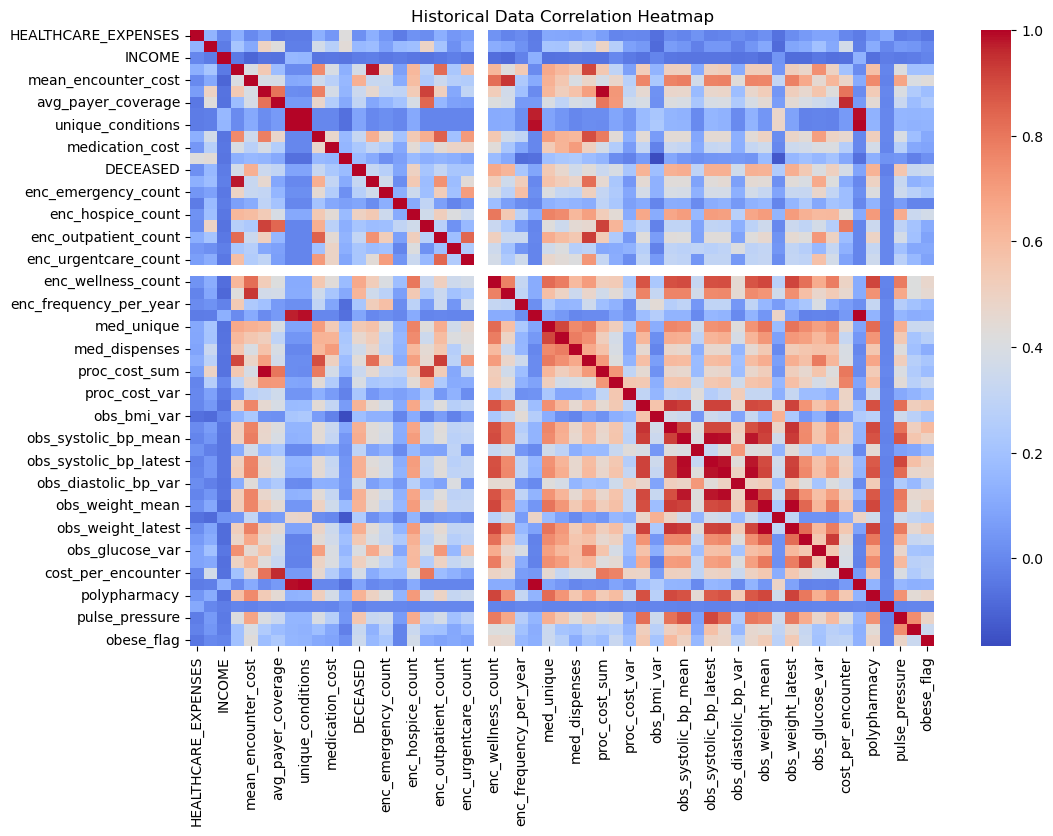

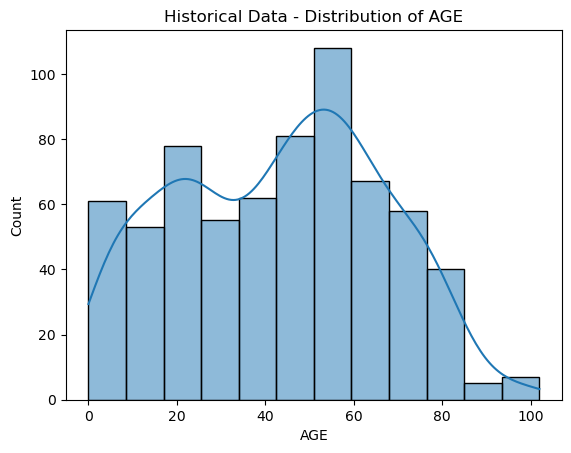

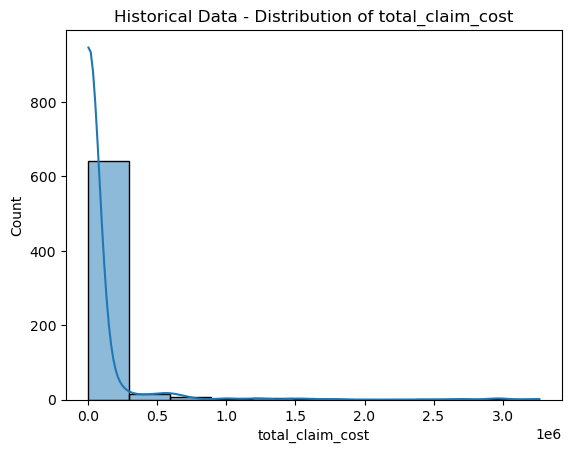

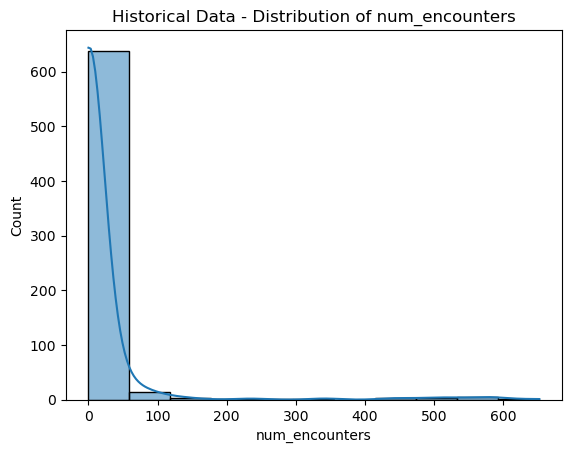

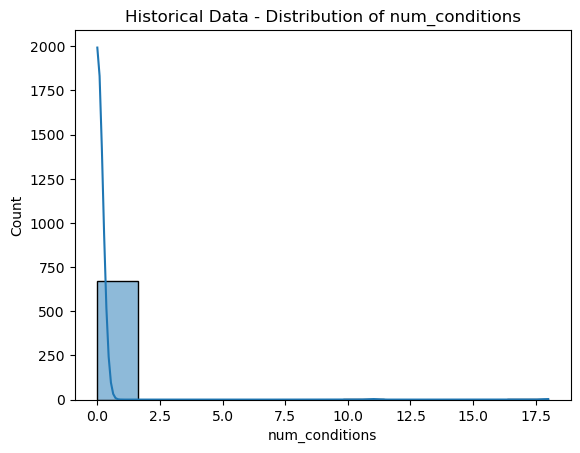

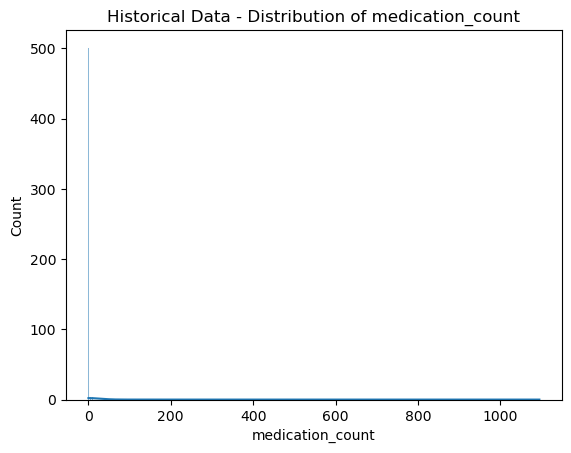

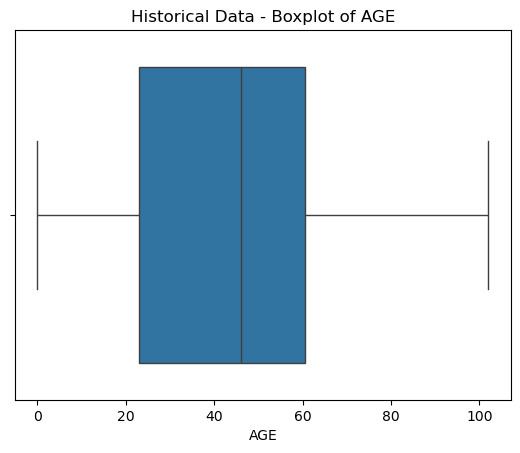

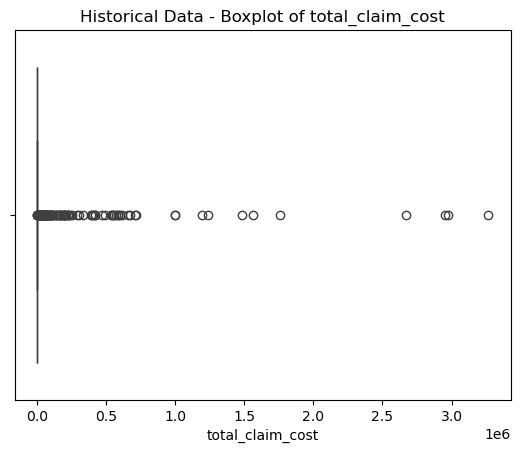

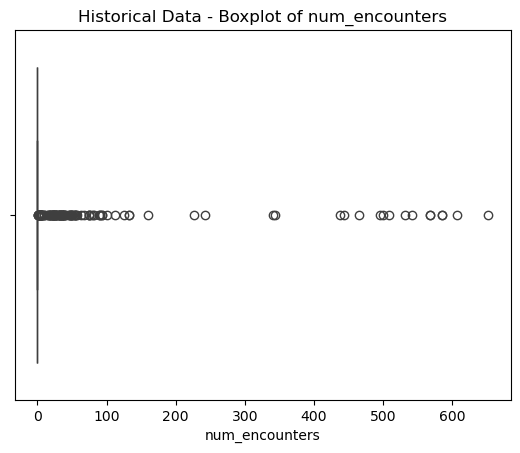

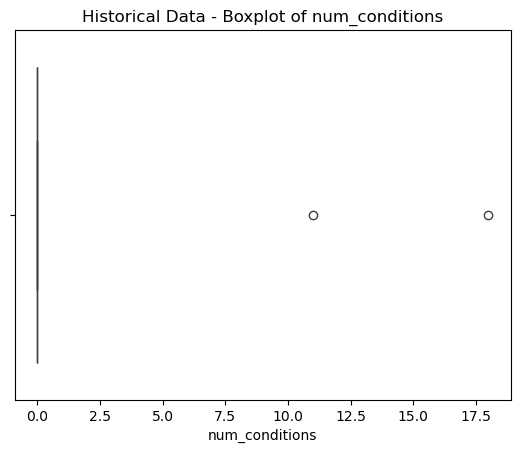

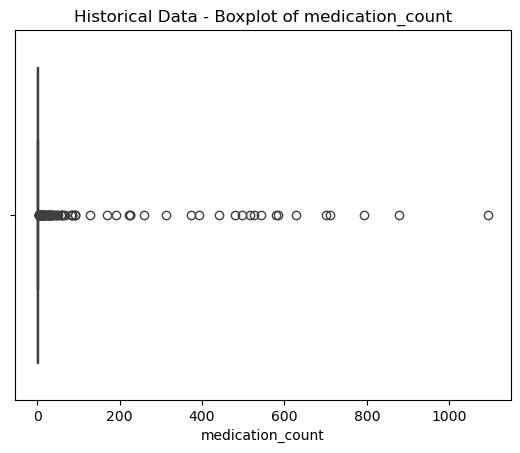

In [293]:
run_eda(historical_eda, "Historical Data")


===== Current Data EDA =====

Shape: (2148, 67)

Missing Values:
 BIRTHDATE                 0
obs_systolic_bp_latest    0
enc_frequency_per_year    0
condition_active_count    0
med_unique                0
med_active_count          0
med_dispenses             0
proc_count                0
proc_cost_sum             0
proc_cost_mean            0
dtype: int64

Summary Statistics:
                            BIRTHDATE  HEALTHCARE_EXPENSES  \
count                           2148         2.148000e+03   
mean   1983-05-12 05:29:09.720670336         1.807664e+05   
min              1915-05-15 00:00:00         1.000000e+02   
25%              1964-12-18 00:00:00         2.159525e+04   
50%              1983-10-22 00:00:00         9.594507e+04   
75%              2003-04-13 12:00:00         2.181095e+05   
max              2026-03-23 00:00:00         1.773785e+06   
std                              NaN         2.426084e+05   

       HEALTHCARE_COVERAGE         INCOME  num_encounters  \
count  

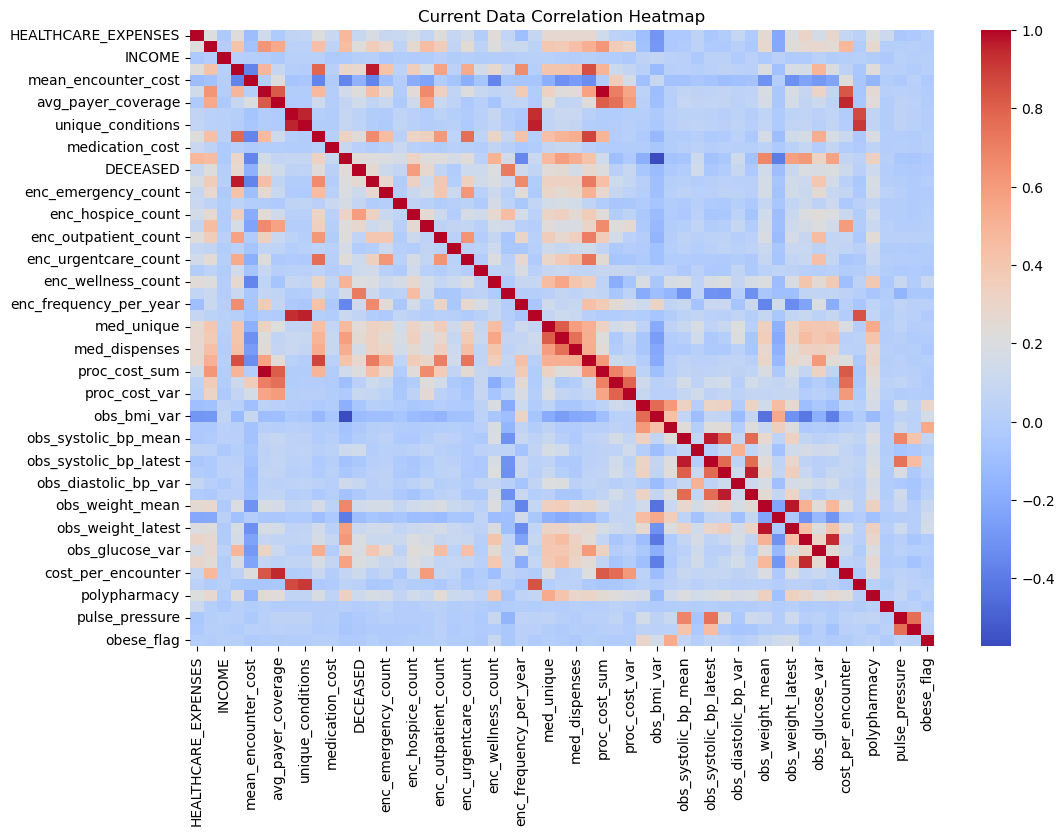

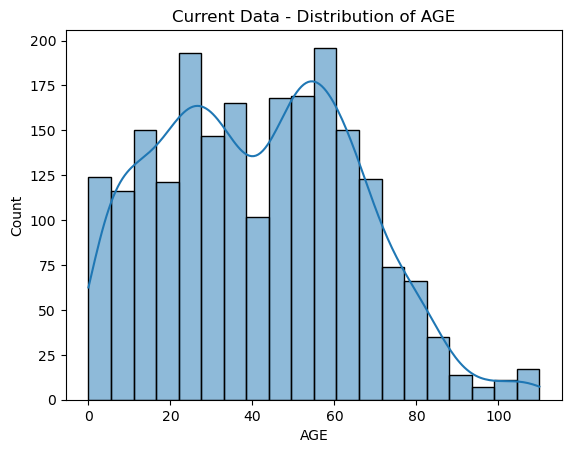

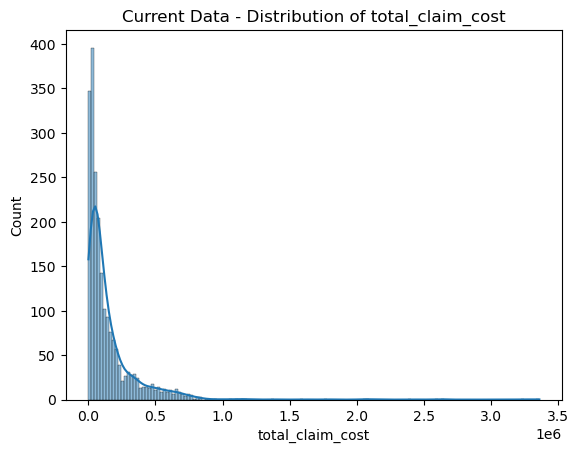

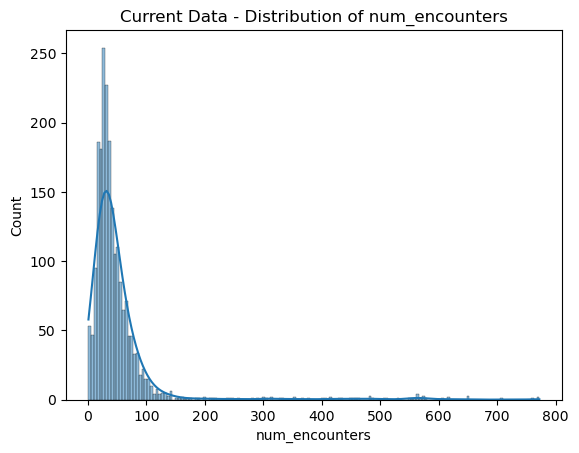

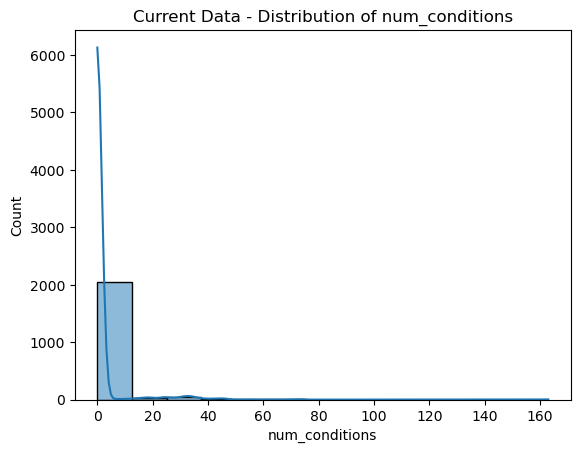

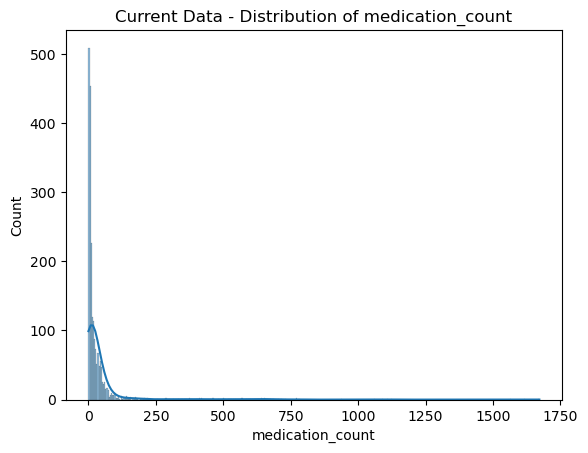

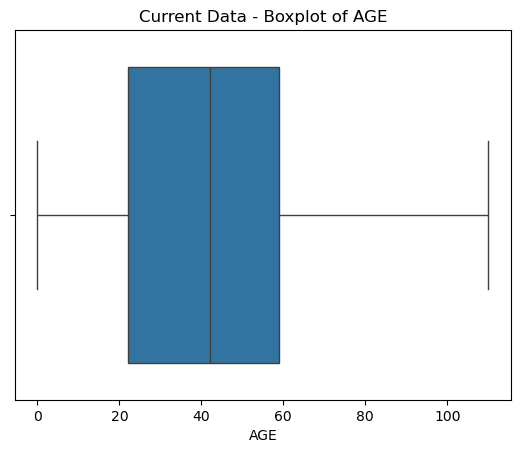

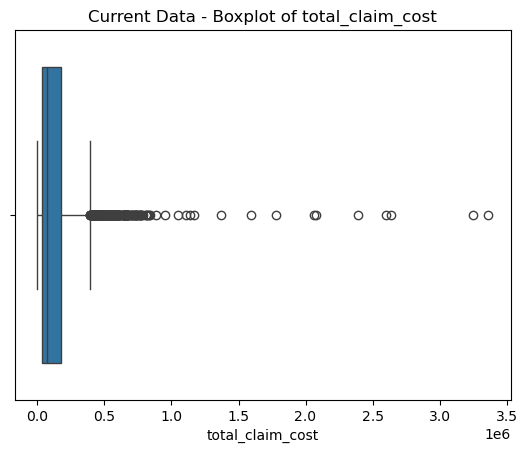

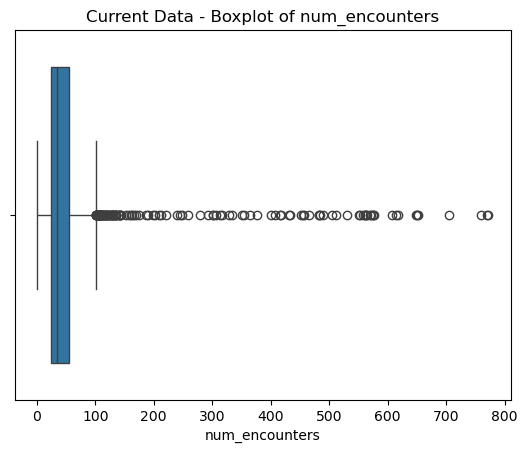

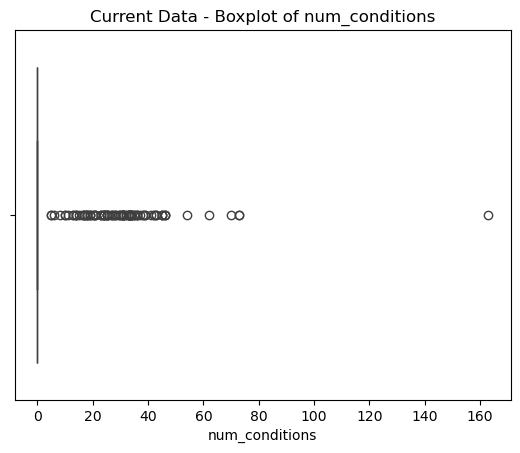

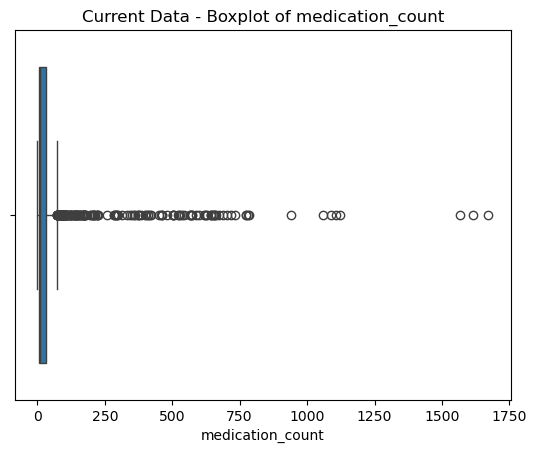

In [294]:
run_eda(current_eda, "Current Data")

In [295]:
comparison = pd.DataFrame({
    'historical_mean': historical_eda.mean(numeric_only=True),
    'current_mean': current_eda.mean(numeric_only=True)
})

comparison['difference'] = comparison['current_mean'] - comparison['historical_mean']


print("\nTop Increases:")
print(comparison.sort_values('difference', ascending=False).head(10))


print("\nTop Decreases:")
print(comparison.sort_values('difference').head(10))


Top Increases:
                    historical_mean  current_mean    difference
proc_cost_var          1.942144e+06  3.798028e+06  1.855883e+06
medication_cost        9.864225e+03  1.647138e+05  1.548495e+05
total_claim_cost       5.869659e+04  1.492105e+05  9.051389e+04
proc_cost_sum          5.803789e+04  1.452574e+05  8.721955e+04
INCOME                 1.018350e+05  1.158533e+05  1.401838e+04
cost_per_encounter     6.790734e+02  2.603277e+03  1.924204e+03
avg_payer_coverage     5.013778e+02  1.753088e+03  1.251710e+03
proc_cost_mean         2.128205e+02  8.939657e+02  6.811452e+02
med_dispenses          1.163970e+02  3.412742e+02  2.248772e+02
obs_bmi_var            2.203235e+01  2.021770e+02  1.801447e+02

Top Decreases:
                         historical_mean   current_mean    difference
HEALTHCARE_COVERAGE        359796.127067  324214.924846 -35581.202220
HEALTHCARE_EXPENSES        187441.511052  180766.447528  -6675.063524
days_since_last_enc          2915.905185     598.53072

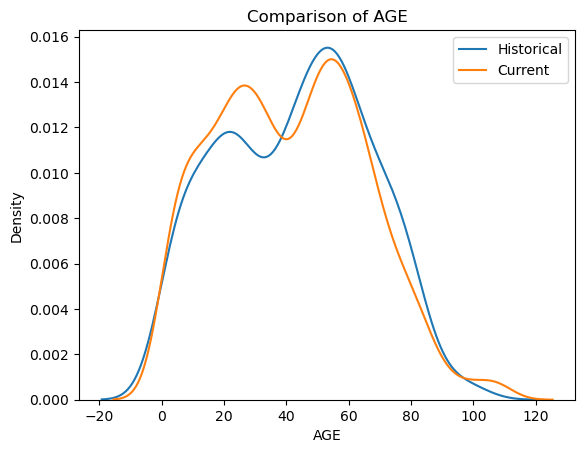

<Figure size 640x480 with 0 Axes>

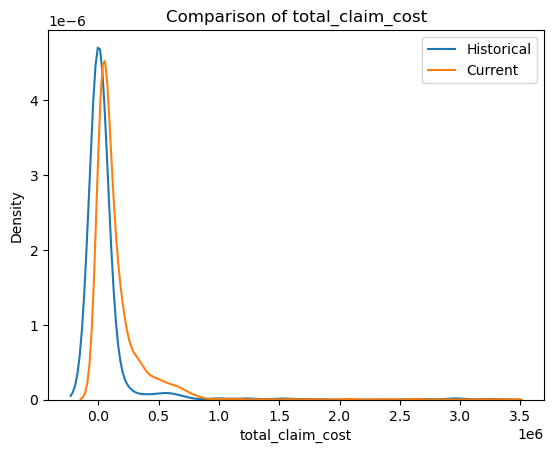

<Figure size 640x480 with 0 Axes>

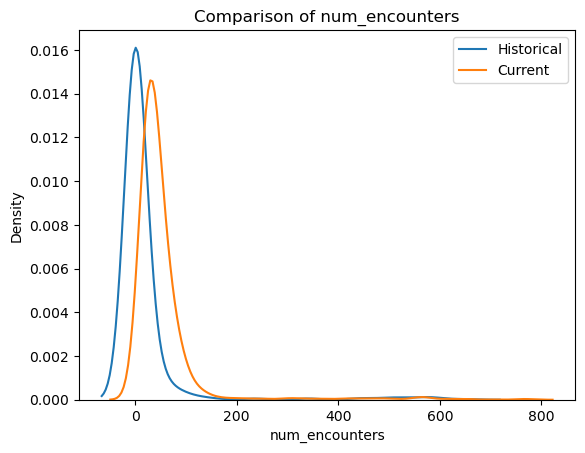

<Figure size 640x480 with 0 Axes>

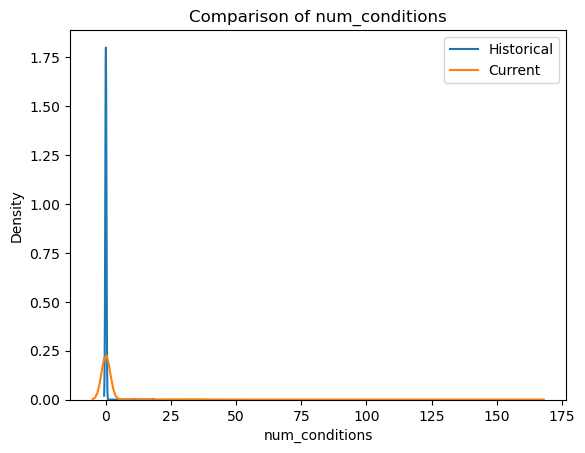

<Figure size 640x480 with 0 Axes>

In [296]:
def compare_distributions(col):
    plt.figure()
    sns.kdeplot(historical_eda[col], label='Historical')
    sns.kdeplot(current_eda[col], label='Current')
    plt.title(f"Comparison of {col}")
    plt.legend()
    plt.show()
    plt.savefig(f"{col}_comparison.png")

for col in ['AGE', 'total_claim_cost', 'num_encounters', 'num_conditions']:
    if col in historical_eda.columns:
        compare_distributions(col)

/tmp/ipykernel_95984/2757810782.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  historical_eda['severity_group']='Low'


<AxesSubplot: xlabel='severity_group', ylabel='total_claim_cost'>

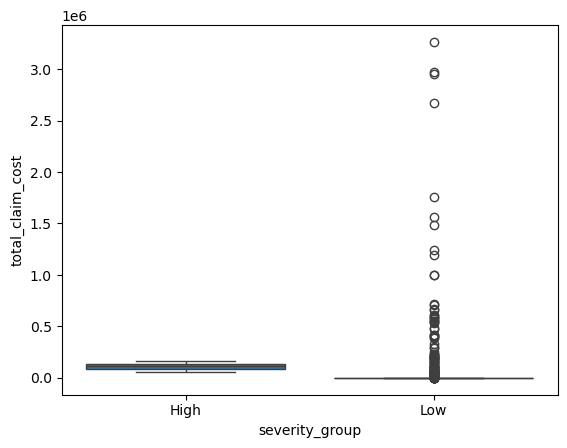

In [297]:
historical_eda['severity_group']='Low'

historical_eda.loc[
historical_eda['num_conditions']>=3,
'severity_group'
]='High'

sns.boxplot(
data=historical_eda,
x='severity_group',
y='total_claim_cost')

/tmp/ipykernel_95984/2034016685.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  current_eda['severity_group']='Low'


<AxesSubplot: xlabel='severity_group', ylabel='total_claim_cost'>

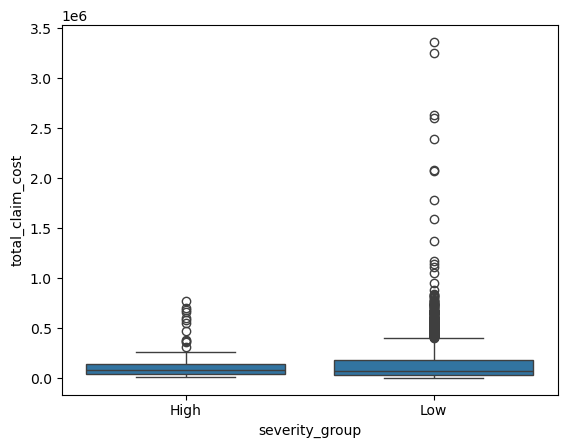

In [298]:
current_eda['severity_group']='Low'

current_eda.loc[
current_eda['num_conditions']>=3,
'severity_group'
]='High'

sns.boxplot(
data=current_eda,
x='severity_group',
y='total_claim_cost')

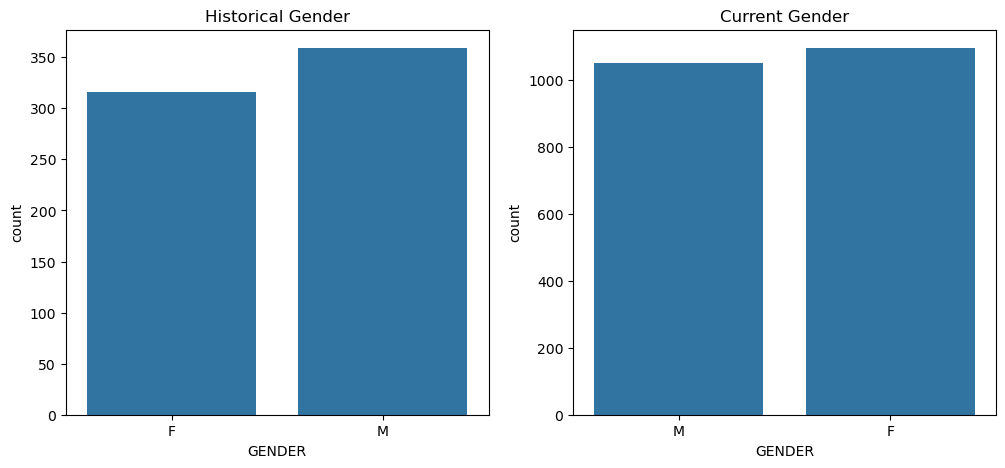

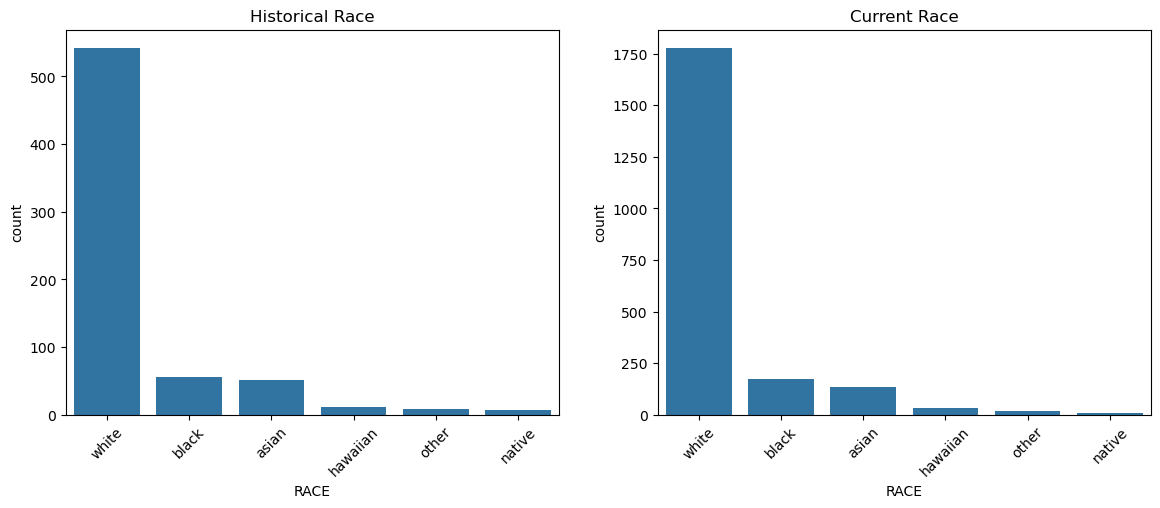

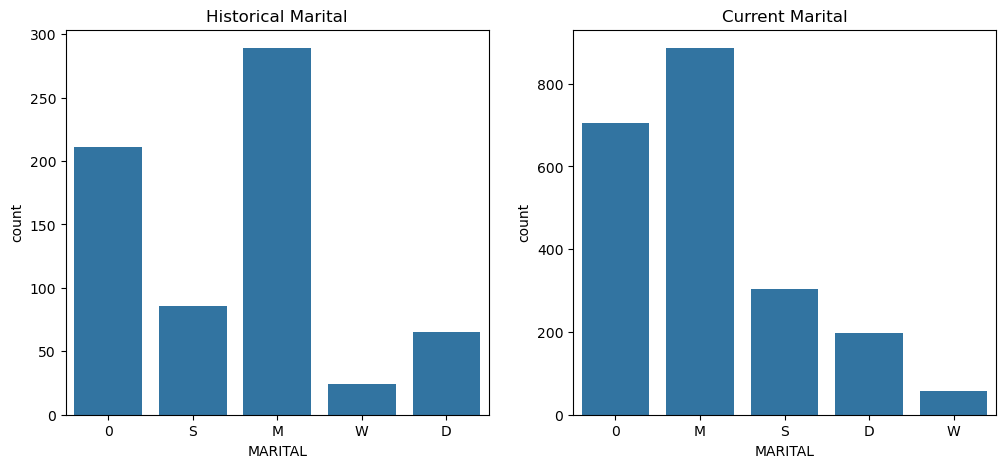

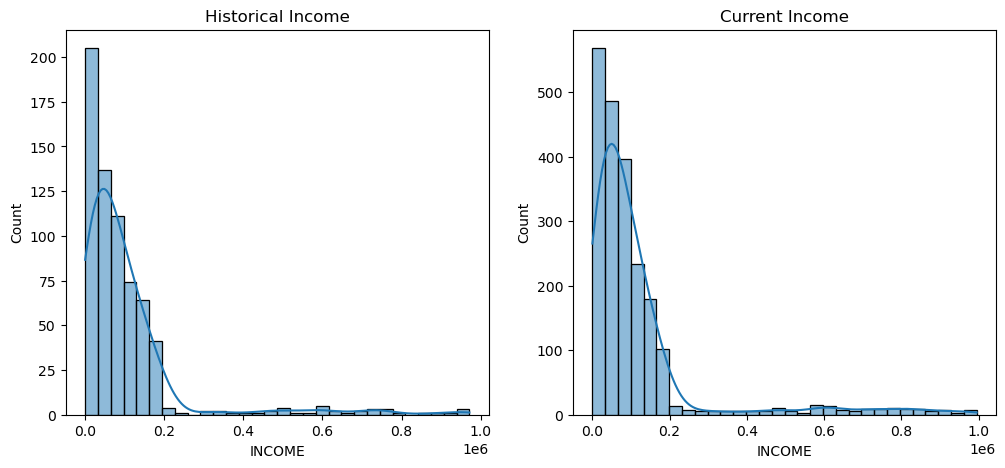

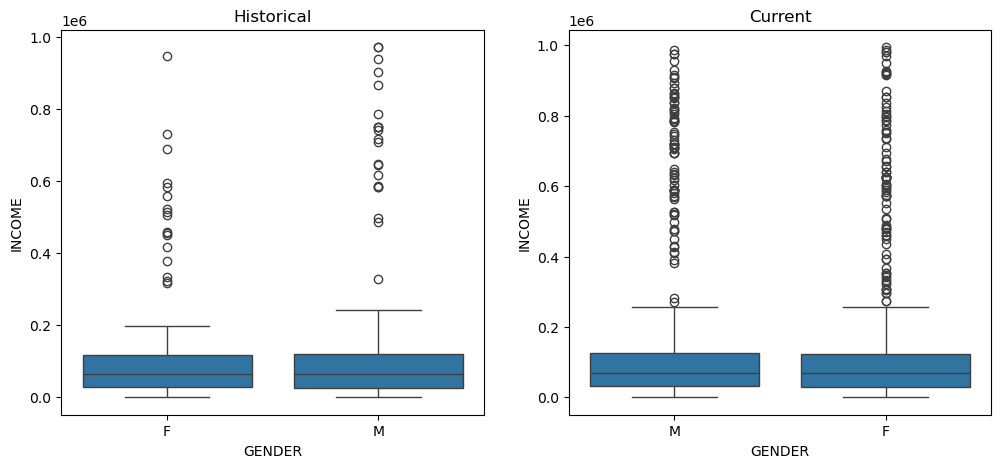

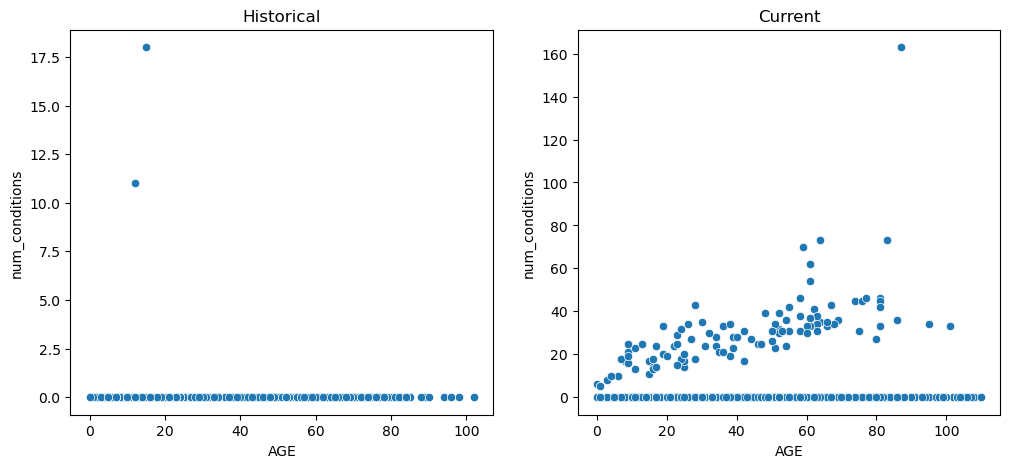

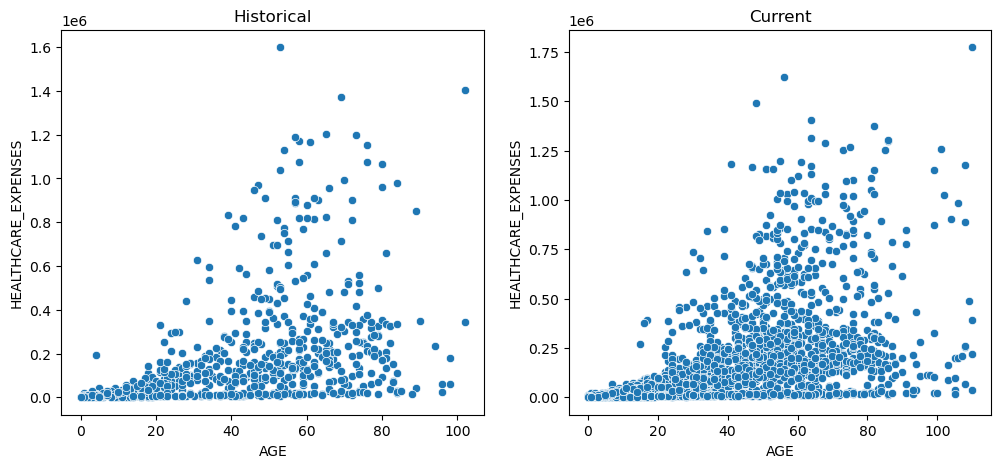

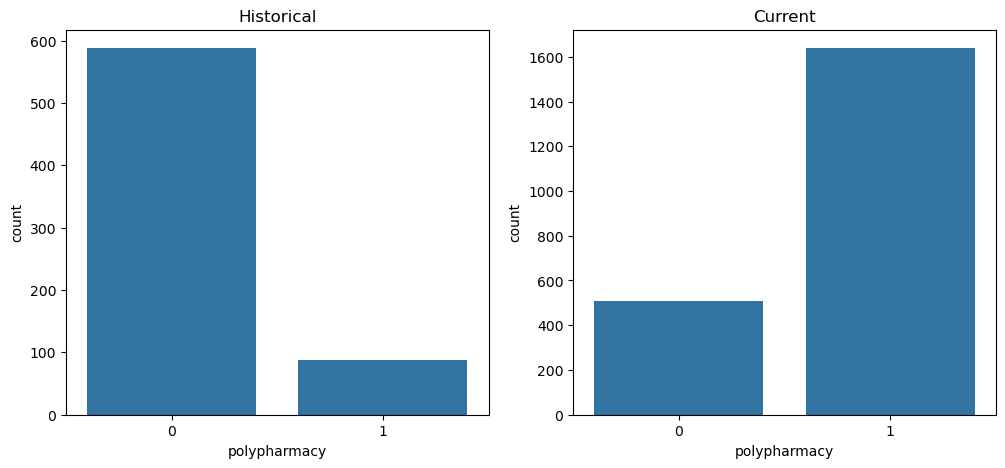

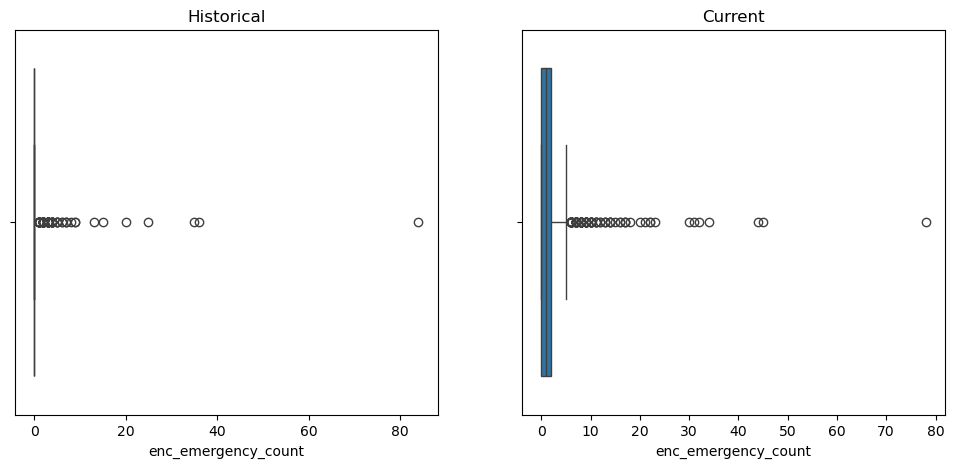

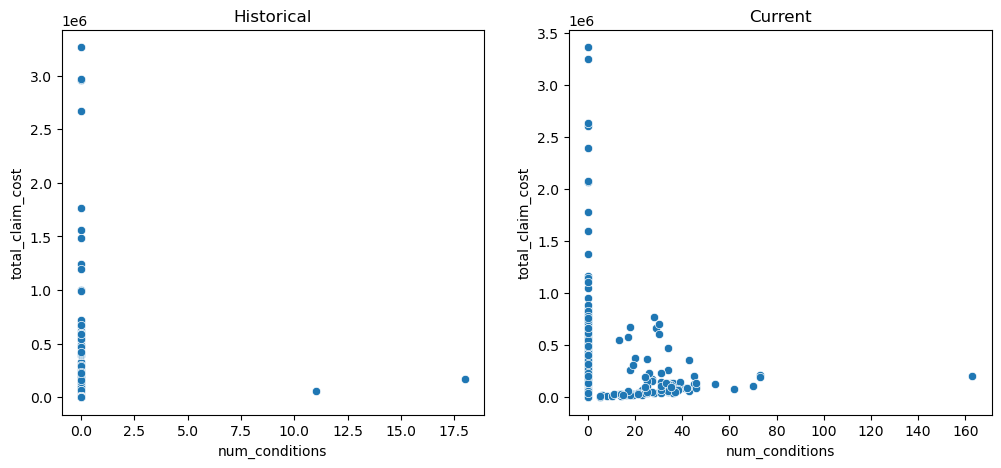

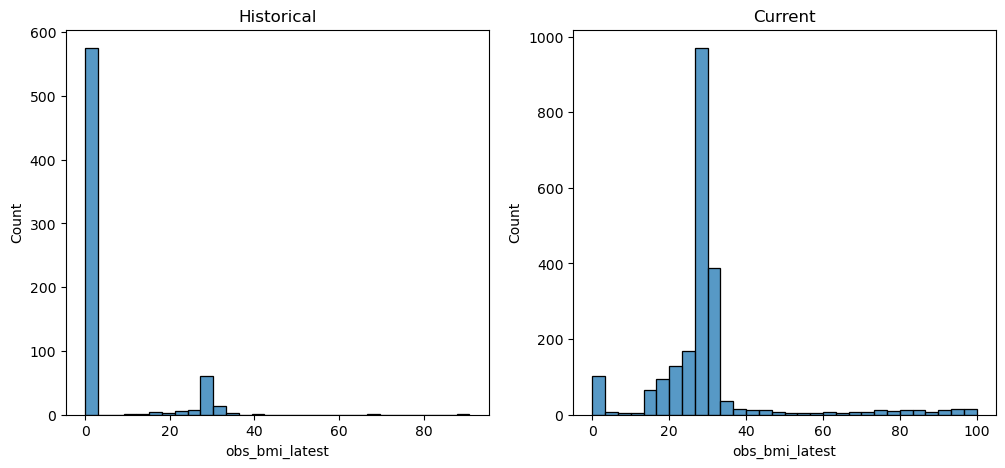

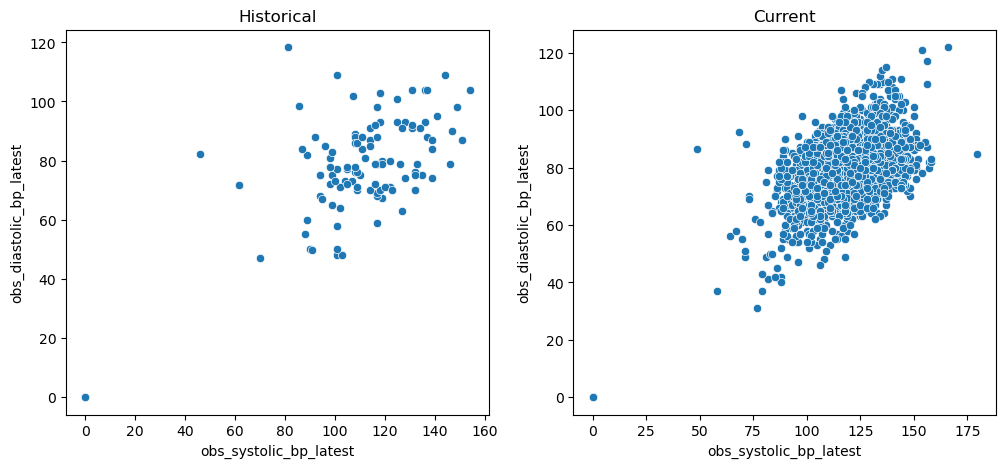

In [299]:
import matplotlib.pyplot as plt
import seaborn as sns


fig, axes = plt.subplots(1,2, figsize=(12,5))

sns.countplot(data=historical_eda,x='GENDER',ax=axes[0])
axes[0].set_title('Historical Gender')

sns.countplot(data=current_eda,x='GENDER',ax=axes[1])
axes[1].set_title('Current Gender')

plt.show()


fig, axes = plt.subplots(1,2, figsize=(14,5))

sns.countplot(
data=historical_eda,
x='RACE',
order=historical_eda['RACE'].value_counts().index,
ax=axes[0]
)
axes[0].tick_params(axis='x',rotation=45)
axes[0].set_title('Historical Race')

sns.countplot(
data=current_eda,
x='RACE',
order=current_eda['RACE'].value_counts().index,
ax=axes[1]
)
axes[1].tick_params(axis='x',rotation=45)
axes[1].set_title('Current Race')

plt.show()



fig, axes = plt.subplots(1,2, figsize=(12,5))

sns.countplot(data=historical_eda,x='MARITAL',ax=axes[0])
axes[0].set_title('Historical Marital')

sns.countplot(data=current_eda,x='MARITAL',ax=axes[1])
axes[1].set_title('Current Marital')

plt.show()



fig, axes = plt.subplots(1,2, figsize=(12,5))

sns.histplot(historical_eda['INCOME'],bins=30,kde=True,ax=axes[0])
axes[0].set_title('Historical Income')

sns.histplot(current_eda['INCOME'],bins=30,kde=True,ax=axes[1])
axes[1].set_title('Current Income')

plt.show()



fig, axes = plt.subplots(1,2, figsize=(12,5))

sns.boxplot(data=historical_eda,x='GENDER',y='INCOME',ax=axes[0])
axes[0].set_title('Historical')

sns.boxplot(data=current_eda,x='GENDER',y='INCOME',ax=axes[1])
axes[1].set_title('Current')

plt.show()


fig, axes = plt.subplots(1,2, figsize=(12,5))

sns.scatterplot(
data=historical_eda,
x='AGE',
y='num_conditions',
ax=axes[0]
)

sns.scatterplot(
data=current_eda,
x='AGE',
y='num_conditions',
ax=axes[1]
)

axes[0].set_title('Historical')
axes[1].set_title('Current')
plt.show()



fig, axes = plt.subplots(1,2, figsize=(12,5))

sns.scatterplot(
data=historical_eda,
x='AGE',
y='HEALTHCARE_EXPENSES',
ax=axes[0]
)

sns.scatterplot(
data=current_eda,
x='AGE',
y='HEALTHCARE_EXPENSES',
ax=axes[1]
)

axes[0].set_title('Historical')
axes[1].set_title('Current')
plt.show()


fig, axes = plt.subplots(1,2, figsize=(12,5))

sns.countplot(data=historical_eda,x='polypharmacy',ax=axes[0])
sns.countplot(data=current_eda,x='polypharmacy',ax=axes[1])

axes[0].set_title('Historical')
axes[1].set_title('Current')

plt.show()



fig, axes = plt.subplots(1,2, figsize=(12,5))

sns.boxplot(
x=historical_eda['enc_emergency_count'],
ax=axes[0]
)

sns.boxplot(
x=current_eda['enc_emergency_count'],
ax=axes[1]
)

axes[0].set_title('Historical')
axes[1].set_title('Current')

plt.show()



fig, axes = plt.subplots(1,2, figsize=(12,5))

sns.scatterplot(
data=historical_eda,
x='num_conditions',
y='total_claim_cost',
ax=axes[0]
)

sns.scatterplot(
data=current_eda,
x='num_conditions',
y='total_claim_cost',
ax=axes[1]
)

axes[0].set_title('Historical')
axes[1].set_title('Current')
plt.show()


fig, axes = plt.subplots(1,2, figsize=(12,5))

sns.histplot(
historical_eda['obs_bmi_latest'],
bins=30,
ax=axes[0]
)

sns.histplot(
current_eda['obs_bmi_latest'],
bins=30,
ax=axes[1]
)

axes[0].set_title('Historical')
axes[1].set_title('Current')
plt.show()


fig, axes = plt.subplots(1,2, figsize=(12,5))

sns.scatterplot(
data=historical_eda,
x='obs_systolic_bp_latest',
y='obs_diastolic_bp_latest',
ax=axes[0]
)

sns.scatterplot(
data=current_eda,
x='obs_systolic_bp_latest',
y='obs_diastolic_bp_latest',
ax=axes[1]
)

axes[0].set_title('Historical')
axes[1].set_title('Current')
plt.show()




**Train Test Split**

In [300]:
historical.columns

Index(['BIRTHDATE', 'DEATHDATE', 'PREFIX', 'BIRTHPLACE', 'COUNTY',
       'HEALTHCARE_EXPENSES', 'HEALTHCARE_COVERAGE', 'INCOME',
       'num_encounters', 'mean_encounter_cost',
       ...
       'CITY_Winchendon', 'CITY_Winchester', 'CITY_Winthrop', 'CITY_Woburn',
       'CITY_Woods Hole', 'CITY_Worcester', 'CITY_Worthington',
       'CITY_Wrentham', 'CITY_Yarmouth', 'CITY_Yarmouth Port'],
      dtype='object', length=409)

In [301]:
from sklearn.model_selection import train_test_split

TARGET = 'pulse_flag'  


X_d1 = historical.drop(columns=[TARGET])
y_d1 = historical[TARGET]

X_d1_train, X_d1_test, y_d1_train, y_d1_test = train_test_split(
    X_d1, y_d1,
    test_size=0.2,
    # stratify=y_d1,
    random_state=42
)

print("Dataset1 Train:", X_d1_train.shape)
print("Dataset1 Test :", X_d1_test.shape)



X_d2 = current.drop(columns=[TARGET])
y_d2 = current[TARGET]

X_d2_train, X_d2_test, y_d2_train, y_d2_test = train_test_split(
    X_d2, y_d2,
    test_size=0.2,
    # stratify=y_d2,
    random_state=42
)
X_d1 = X_d1.drop(columns=['pulse_pressure'], errors='ignore')
X_d2 = X_d2.drop(columns=['pulse_pressure'], errors='ignore')
print("\nDataset2 Train:", X_d2_train.shape)
print("Dataset2 Test :", X_d2_test.shape)

id_cols = ['LAST_ENCOUNTER']   # add more if needed

X_d1_train = X_d1_train.select_dtypes(include=[np.number])
X_d1_test  = X_d1_test.select_dtypes(include=[np.number])

X_d2_train = X_d2_train.select_dtypes(include=[np.number])
X_d2_test  = X_d2_test.select_dtypes(include=[np.number])

leak_cols = [
    'obs_bmi_latest',
    # 'obs_bmi_mean',
    'obs_bmi_var',
    'pulse_pressure'
]

X_d1_train = X_d1_train.drop(columns=leak_cols, errors='ignore')
X_d1_test  = X_d1_test.drop(columns=leak_cols, errors='ignore')

X_d2_train = X_d2_train.drop(columns=leak_cols, errors='ignore')
X_d2_test  = X_d2_test.drop(columns=leak_cols, errors='ignore')

from sklearn.preprocessing import StandardScaler


scaler = StandardScaler()


X_d1_train_sc = scaler.fit_transform(X_d1_train)   # fit here
X_d1_test_sc  = scaler.transform(X_d1_test)        # only transform


X_d2_train_sc = scaler.transform(X_d2_train)
X_d2_test_sc  = scaler.transform(X_d2_test)

print(y_d1_train.unique())

Dataset1 Train: (540, 408)
Dataset1 Test : (135, 408)

Dataset2 Train: (1718, 408)
Dataset2 Test : (430, 408)
[0 1]


**Decision Tree**

=== Decision Tree Dataset1 ===
{'Accuracy': 0.9703703703703703, 'Precision': 0.7142857142857143, 'Recall': 0.7142857142857143, 'F1': 0.7142857142857143}

=== Decision Tree Dataset2 ===
{'Accuracy': 0.8162790697674419, 'Precision': 0.6772486772486772, 'Recall': 0.8767123287671232, 'F1': 0.764179104477612}

Confusion Matrix D1:
 [[126   2]
 [  2   5]]
Confusion Matrix D2:
 [[223  61]
 [ 18 128]]


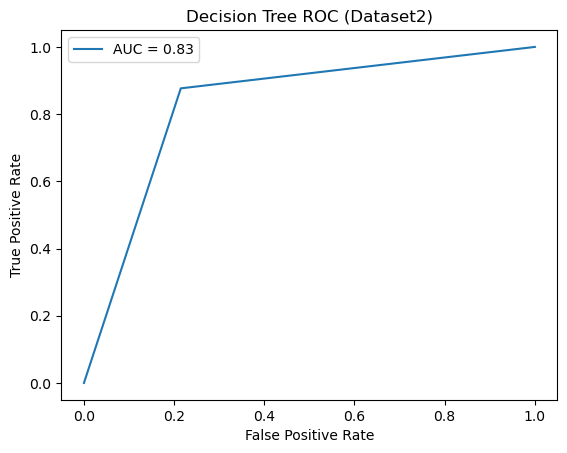


Train Accuracy: 1.0
Test Accuracy: 0.9703703703703703

Depth Analysis:
Depth 2: Train = 0.9851851851851852 Test = 0.9777777777777777
Depth 3: Train = 0.9925925925925926 Test = 0.9629629629629629
Depth 4: Train = 0.9981481481481481 Test = 0.9703703703703703
Depth 5: Train = 1.0 Test = 0.9703703703703703


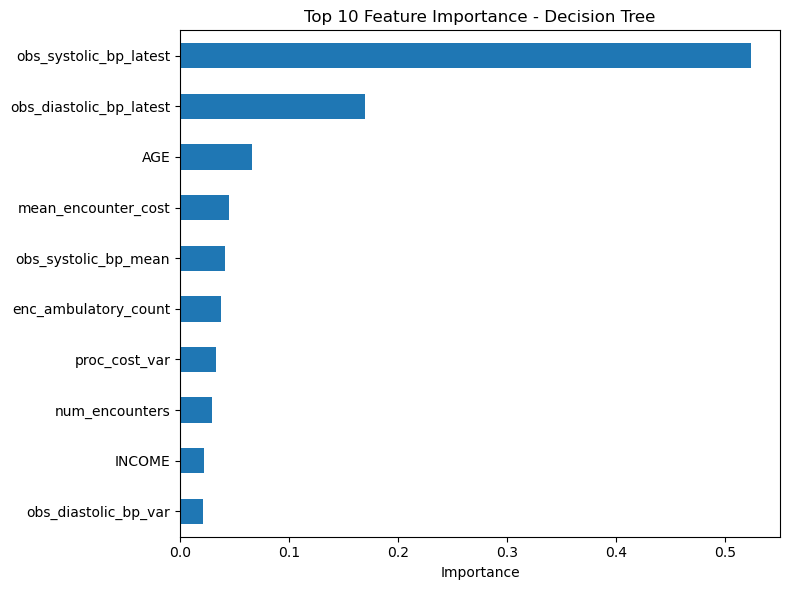

In [302]:


from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, roc_curve, auc
import matplotlib.pyplot as plt
import pandas as pd


dt = DecisionTreeClassifier(max_depth=5, random_state=42)

# Train on Dataset1
dt.fit(X_d1_train, y_d1_train)

# Predictions
y1_pred_dt = dt.predict(X_d1_test)
y2_pred_dt = dt.predict(X_d2_test)


def evaluate(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred)
    }

print("=== Decision Tree Dataset1 ===")
print(evaluate(y_d1_test, y1_pred_dt))

print("\n=== Decision Tree Dataset2 ===")
print(evaluate(y_d2_test, y2_pred_dt))


print("\nConfusion Matrix D1:\n", confusion_matrix(y_d1_test, y1_pred_dt))
print("Confusion Matrix D2:\n", confusion_matrix(y_d2_test, y2_pred_dt))


y_prob_dt = dt.predict_proba(X_d2_test)[:, 1]

fpr, tpr, _ = roc_curve(y_d2_test, y_prob_dt)
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.2f}")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Decision Tree ROC (Dataset2)")
plt.legend()
plt.show()


print("\nTrain Accuracy:", dt.score(X_d1_train, y_d1_train))
print("Test Accuracy:", dt.score(X_d1_test, y_d1_test))


print("\nDepth Analysis:")
for d in [2, 3, 4, 5]:
    model = DecisionTreeClassifier(max_depth=d, random_state=42)
    model.fit(X_d1_train, y_d1_train)

    print(f"Depth {d}:",
          "Train =", model.score(X_d1_train, y_d1_train),
          "Test =", model.score(X_d1_test, y_d1_test))


importance = pd.Series(dt.feature_importances_, index=X_d1_train.columns)

# sort and take top 10
top_features = importance.sort_values(ascending=False).head(10)

plt.figure(figsize=(8,6))
top_features.sort_values().plot(kind='barh')

plt.title("Top 10 Feature Importance - Decision Tree")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()


<Figure size 600x500 with 0 Axes>

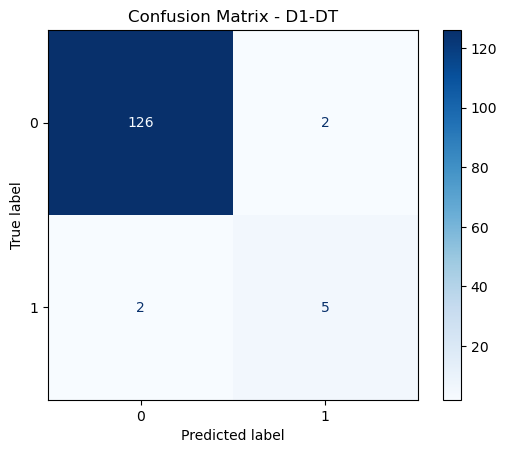

<Figure size 600x500 with 0 Axes>

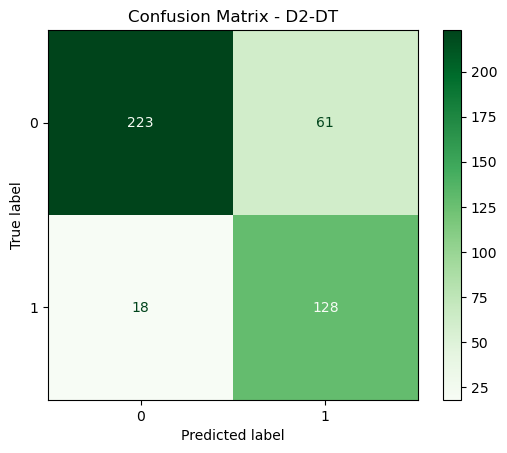

In [303]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt


plt.figure(figsize=(6,5))
ConfusionMatrixDisplay.from_predictions(
    y_d1_test,
    y1_pred_dt,
    cmap='Blues'
)
plt.title('Confusion Matrix - D1-DT')
plt.show()



plt.figure(figsize=(6,5))
ConfusionMatrixDisplay.from_predictions(
    y_d2_test,
    y2_pred_dt,
    cmap='Greens'
)
plt.title('Confusion Matrix - D2-DT')
plt.show()

**SVM**

=== SVM Dataset1 ===
{'Accuracy': 0.9481481481481482, 'Precision': 0.5, 'Recall': 0.14285714285714285, 'F1': 0.2222222222222222}

=== SVM Dataset2 ===
{'Accuracy': 0.6627906976744186, 'Precision': 0.6666666666666666, 'Recall': 0.0136986301369863, 'F1': 0.026845637583892617}
Confusion Matrix D1:
 [[127   1]
 [  6   1]]
Confusion Matrix D2:
 [[283   1]
 [144   2]]


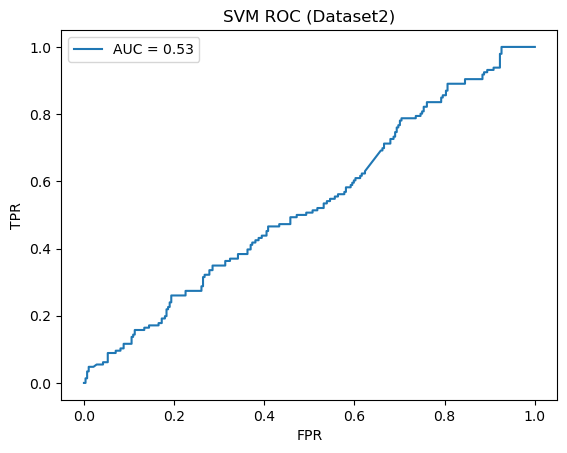

Train Accuracy: 1.0
Test Accuracy: 0.9481481481481482
C=0.1: Train=0.956, Test=0.948
C=1: Train=0.978, Test=0.948
C=10: Train=1.000, Test=0.948
C=100: Train=1.000, Test=0.956
C=1000: Train=1.000, Test=0.956
gamma=0.01: Train=0.967, Test=0.948
gamma=0.1: Train=0.994, Test=0.948
gamma=1: Train=1.000, Test=0.948
gamma=10: Train=1.000, Test=0.948


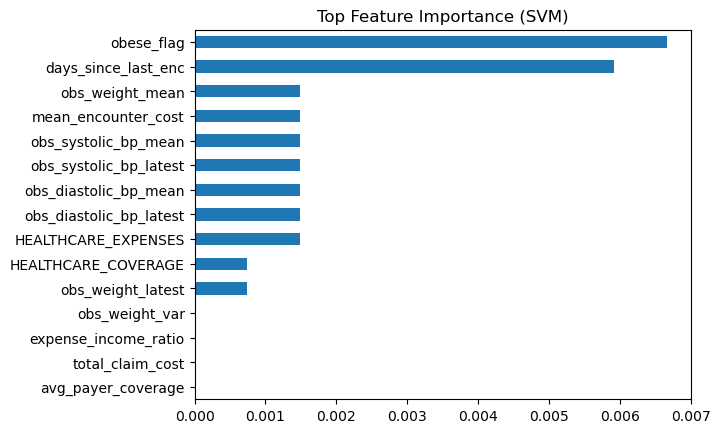

In [304]:

from sklearn.svm import SVC

svm = SVC(
    kernel='rbf',
    C=10,
    gamma=0.1,
    probability=True,
    class_weight='balanced'
)


svm.fit(X_d1_train_sc, y_d1_train)


y_d1_pred_svm = svm.predict(X_d1_test_sc)
y_d2_pred_svm = svm.predict(X_d2_test_sc)


from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def evaluate(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred)
    }

print("=== SVM Dataset1 ===")
print(evaluate(y_d1_test, y_d1_pred_svm))

print("\n=== SVM Dataset2 ===")
print(evaluate(y_d2_test, y_d2_pred_svm))



from sklearn.metrics import confusion_matrix

print("Confusion Matrix D1:\n", confusion_matrix(y_d1_test, y_d1_pred_svm))
print("Confusion Matrix D2:\n", confusion_matrix(y_d2_test, y_d2_pred_svm))



from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

y_prob = svm.predict_proba(X_d2_test_sc)[:,1]

y_pred_adj = (y_prob > 0.3).astype(int)   # try 0.2–0.3

fpr, tpr, _ = roc_curve(y_d2_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.2f}")
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.title("SVM ROC (Dataset2)")
plt.legend()
plt.show()



print("Train Accuracy:", svm.score(X_d1_train_sc, y_d1_train))
print("Test Accuracy:", svm.score(X_d1_test_sc, y_d1_test))



for C_val in [0.1, 1, 10, 100,1000]:
    model = SVC(kernel='rbf', C=C_val, gamma='scale')
    model.fit(X_d1_train_sc, y_d1_train)

    train_acc = model.score(X_d1_train_sc, y_d1_train)
    test_acc = model.score(X_d1_test_sc, y_d1_test)

    print(f"C={C_val}: Train={train_acc:.3f}, Test={test_acc:.3f}")


for g in [0.01, 0.1, 1,10]:
    model = SVC(kernel='rbf', C=1, gamma=g)
    model.fit(X_d1_train_sc, y_d1_train)

    train_acc = model.score(X_d1_train_sc, y_d1_train)
    test_acc = model.score(X_d1_test_sc, y_d1_test)

    print(f"gamma={g}: Train={train_acc:.3f}, Test={test_acc:.3f}")



from sklearn.inspection import permutation_importance
import pandas as pd

result = permutation_importance(
    svm,
    X_d1_test_sc,
    y_d1_test,
    n_repeats=10,
    random_state=42
)

importance = pd.Series(result.importances_mean, index=X_d1_train.columns)
importance.sort_values().tail(15).plot(kind='barh')

plt.title("Top Feature Importance (SVM)")
plt.show()

<Figure size 600x500 with 0 Axes>

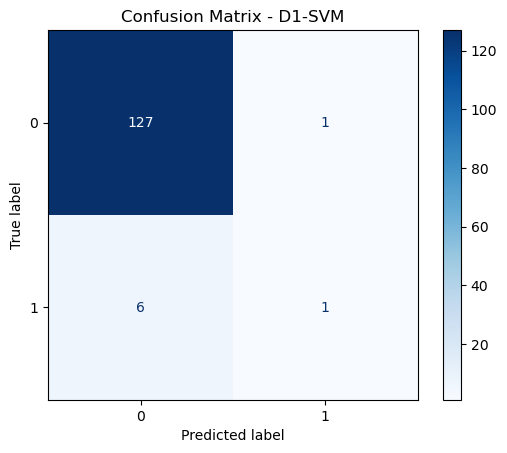

<Figure size 600x500 with 0 Axes>

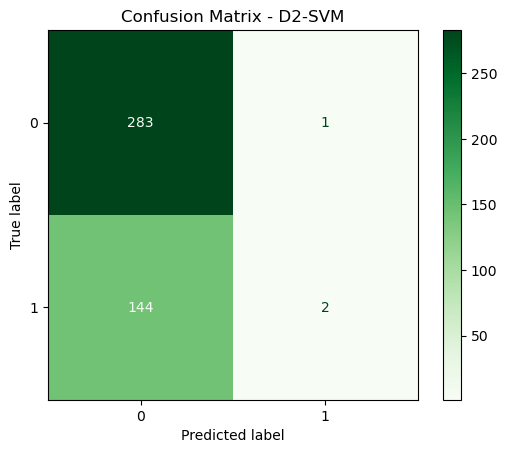

In [305]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt


plt.figure(figsize=(6,5))
ConfusionMatrixDisplay.from_predictions(
    y_d1_test,
    y_d1_pred_svm,
    cmap='Blues'
)
plt.title('Confusion Matrix - D1-SVM')
plt.show()



plt.figure(figsize=(6,5))
ConfusionMatrixDisplay.from_predictions(
    y_d2_test,
    y_d2_pred_svm,
    cmap='Greens'
)
plt.title('Confusion Matrix - D2-SVM')
plt.show()

In [306]:
print(y_d1_train.value_counts())
print(y_d1_test.value_counts())

pulse_flag
0    516
1     24
Name: count, dtype: int64
pulse_flag
0    128
1      7
Name: count, dtype: int64


**MLP**

=== MLP Dataset1 ===
{'Accuracy': 0.9333333333333333, 'Precision': 0.3333333333333333, 'Recall': 0.2857142857142857, 'F1': 0.3076923076923077}

=== MLP Dataset2 ===
{'Accuracy': 0.6162790697674418, 'Precision': 0.42016806722689076, 'Recall': 0.3424657534246575, 'F1': 0.37735849056603776}

Confusion Matrix D1:
 [[124   4]
 [  5   2]]
Confusion Matrix D2:
 [[215  69]
 [ 96  50]]


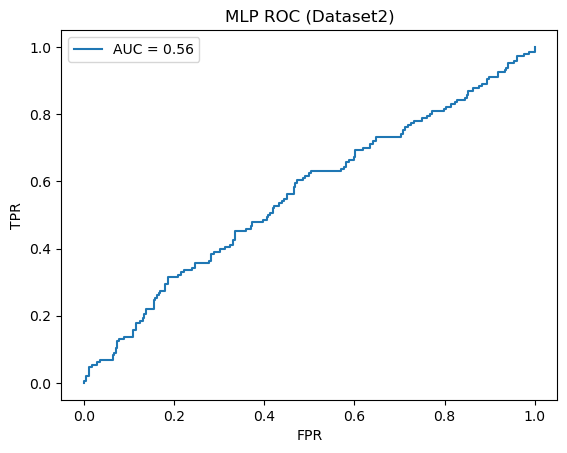

Train Accuracy: 0.9981481481481481
Test Accuracy: 0.9333333333333333
Layers (2,): Train = 0.9574074074074074 Test = 0.9481481481481482
Layers (4,): Train = 0.9925925925925926 Test = 0.9407407407407408
Layers (8,): Train = 0.9962962962962963 Test = 0.9407407407407408
Layers (8, 4): Train = 0.9888888888888889 Test = 0.9333333333333333
Layers (12, 6): Train = 0.9962962962962963 Test = 0.9259259259259259


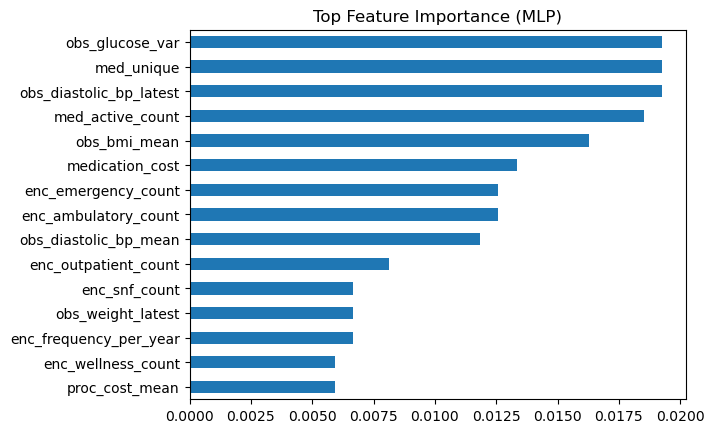

In [307]:

from sklearn.neural_network import MLPClassifier

mlp = MLPClassifier(
    hidden_layer_sizes=(16, 8),
    activation='relu',
    solver='adam',
    learning_rate_init=0.001,
    max_iter=5000,
    random_state=42,
)

# Train on Dataset1 (past)
mlp.fit(X_d1_train_sc, y_d1_train)

# Predictions
y_d1_pred_mlp = mlp.predict(X_d1_test_sc)
y_d2_pred_mlp = mlp.predict(X_d2_test_sc)



from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def evaluate(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred)
    }

print("=== MLP Dataset1 ===")
print(evaluate(y_d1_test, y_d1_pred_mlp))

print("\n=== MLP Dataset2 ===")
print(evaluate(y_d2_test, y_d2_pred_mlp))

historical.columns

from sklearn.metrics import confusion_matrix

print("\nConfusion Matrix D1:\n", confusion_matrix(y_d1_test, y_d1_pred_mlp))
print("Confusion Matrix D2:\n", confusion_matrix(y_d2_test, y_d2_pred_mlp))



from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

y_prob_mlp = mlp.predict_proba(X_d2_test_sc)[:,1]

fpr, tpr, _ = roc_curve(y_d2_test, y_prob_mlp)
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.2f}")
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.title("MLP ROC (Dataset2)")
plt.legend()
plt.show()



print("Train Accuracy:", mlp.score(X_d1_train_sc, y_d1_train))
print("Test Accuracy:", mlp.score(X_d1_test_sc, y_d1_test))



for layers in [(2,),(4,), (8,), (8,4), (12,6)]:
    model = MLPClassifier(hidden_layer_sizes=layers, max_iter=1000, random_state=42)
    model.fit(X_d1_train_sc, y_d1_train)

    print(f"Layers {layers}:",
          "Train =", model.score(X_d1_train_sc, y_d1_train),
          "Test =", model.score(X_d1_test_sc, y_d1_test))



from sklearn.inspection import permutation_importance
import pandas as pd

result = permutation_importance(
    mlp,
    X_d1_test_sc,
    y_d1_test,
    n_repeats=10,
    random_state=42
)

importance = pd.Series(result.importances_mean, index=X_d1_train.columns)
importance.sort_values().tail(15).plot(kind='barh')

plt.title("Top Feature Importance (MLP)")
plt.show()

<Figure size 600x500 with 0 Axes>

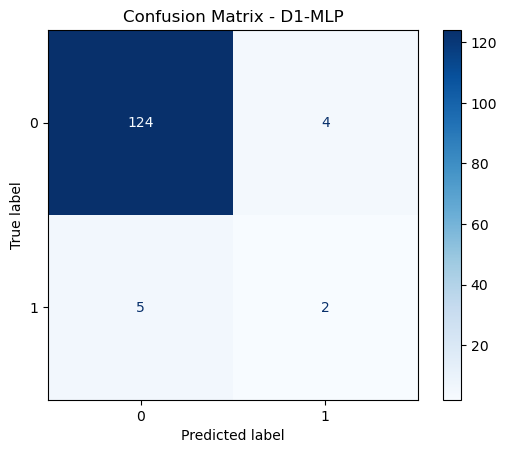

<Figure size 600x500 with 0 Axes>

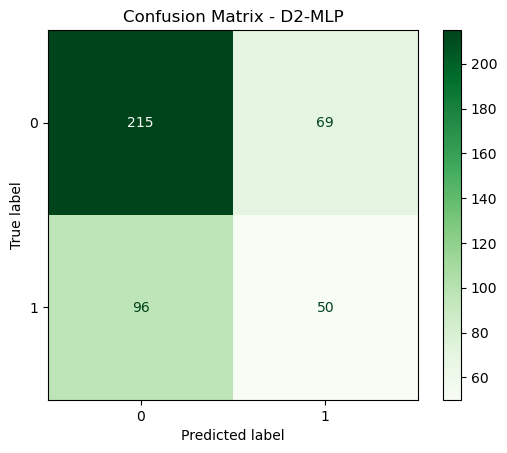

In [308]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt


plt.figure(figsize=(6,5))
ConfusionMatrixDisplay.from_predictions(
    y_d1_test,
    y_d1_pred_mlp,
    cmap='Blues'
)
plt.title('Confusion Matrix - D1-MLP')
plt.show()



plt.figure(figsize=(6,5))
ConfusionMatrixDisplay.from_predictions(
    y_d2_test,
    y_d2_pred_mlp,
    cmap='Greens'
)
plt.title('Confusion Matrix - D2-MLP')
plt.show()

In [309]:
historical.columns

Index(['BIRTHDATE', 'DEATHDATE', 'PREFIX', 'BIRTHPLACE', 'COUNTY',
       'HEALTHCARE_EXPENSES', 'HEALTHCARE_COVERAGE', 'INCOME',
       'num_encounters', 'mean_encounter_cost',
       ...
       'CITY_Winchendon', 'CITY_Winchester', 'CITY_Winthrop', 'CITY_Woburn',
       'CITY_Woods Hole', 'CITY_Worcester', 'CITY_Worthington',
       'CITY_Wrentham', 'CITY_Yarmouth', 'CITY_Yarmouth Port'],
      dtype='object', length=409)

Continual Training(DT)

=== DECISION TREE CONTINUAL LEARNING COMPARISON ===

BEFORE CONTINUAL LEARNING:
Accuracy : 0.8209
Precision: 0.6788
Recall   : 0.8973
F1 Score : 0.7729
AUC      : 0.8423

AFTER CONTINUAL LEARNING:
Accuracy : 0.8395
Precision: 0.8532
Recall   : 0.6370
F1 Score : 0.7294
AUC      : 0.8604


/usr/lib/python3/dist-packages/sklearn/base.py:486: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
/usr/lib/python3/dist-packages/sklearn/base.py:486: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(


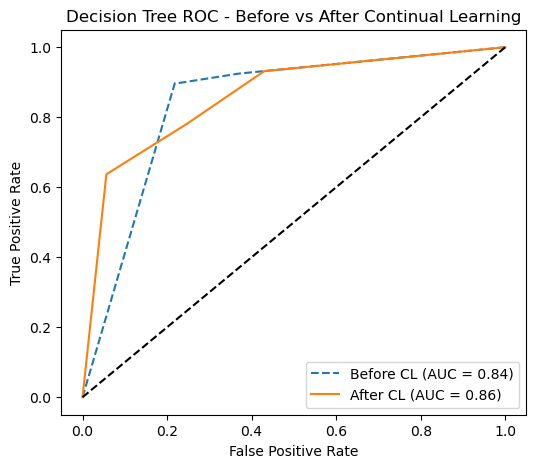

In [310]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_curve, auc
)

dt_base = DecisionTreeClassifier(max_depth=2, random_state=42)


dt_base.fit(X_d1_train, y_d1_train)


y_pred_before = dt_base.predict(X_d2_test)
y_prob_before = dt_base.predict_proba(X_d2_test)[:,1]

acc_before = accuracy_score(y_d2_test, y_pred_before)
prec_before = precision_score(y_d2_test, y_pred_before)
rec_before = recall_score(y_d2_test, y_pred_before)
f1_before = f1_score(y_d2_test, y_pred_before)

fpr_b, tpr_b, _ = roc_curve(y_d2_test, y_prob_before)
auc_before = auc(fpr_b, tpr_b)



X_combined = np.vstack([X_d1_train, X_d2_train])
y_combined = np.concatenate([y_d1_train, y_d2_train])

dt_cl = DecisionTreeClassifier(max_depth=2, random_state=42)
dt_cl.fit(X_combined, y_combined)

y_pred_after = dt_cl.predict(X_d2_test)
y_prob_after = dt_cl.predict_proba(X_d2_test)[:,1]

acc_after = accuracy_score(y_d2_test, y_pred_after)
prec_after = precision_score(y_d2_test, y_pred_after)
rec_after = recall_score(y_d2_test, y_pred_after)
f1_after = f1_score(y_d2_test, y_pred_after)

fpr_a, tpr_a, _ = roc_curve(y_d2_test, y_prob_after)
auc_after = auc(fpr_a, tpr_a)

print("=== DECISION TREE CONTINUAL LEARNING COMPARISON ===\n")

print("BEFORE CONTINUAL LEARNING:")
print(f"Accuracy : {acc_before:.4f}")
print(f"Precision: {prec_before:.4f}")
print(f"Recall   : {rec_before:.4f}")
print(f"F1 Score : {f1_before:.4f}")
print(f"AUC      : {auc_before:.4f}\n")

print("AFTER CONTINUAL LEARNING:")
print(f"Accuracy : {acc_after:.4f}")
print(f"Precision: {prec_after:.4f}")
print(f"Recall   : {rec_after:.4f}")
print(f"F1 Score : {f1_after:.4f}")
print(f"AUC      : {auc_after:.4f}")

plt.figure(figsize=(6,5))

plt.plot(fpr_b, tpr_b, label=f"Before CL (AUC = {auc_before:.2f})", linestyle='--')
plt.plot(fpr_a, tpr_a, label=f"After CL (AUC = {auc_after:.2f})")

plt.plot([0,1], [0,1], 'k--')  # random baseline

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Decision Tree ROC - Before vs After Continual Learning")
plt.legend()
plt.show()

Continual Training(SVM)

=== SVM BEFORE === {'Accuracy': 0.6627906976744186, 'Precision': 0.6, 'Recall': 0.02054794520547945, 'F1': 0.039735099337748346, 'AUC': 0.5051369863013698}
=== SVM AFTER  === {'Accuracy': 0.6697674418604651, 'Precision': 0.5140845070422535, 'Recall': 0.5, 'F1': 0.5069444444444444, 'AUC': 0.6947954852402084}


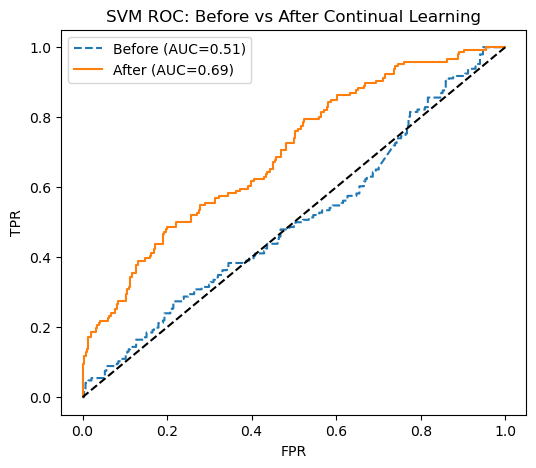

In [311]:
from sklearn.svm import SVC
from sklearn.metrics import *
import numpy as np
import matplotlib.pyplot as plt

svm_base = SVC(kernel='rbf', C=1, gamma=0.1,
               probability=True, class_weight='balanced')

svm_base.fit(X_d1_train_sc, y_d1_train)

y_pred_before = svm_base.predict(X_d2_test_sc)
y_prob_before = svm_base.predict_proba(X_d2_test_sc)[:,1]

X_comb = np.vstack([X_d1_train_sc, X_d2_train_sc])
y_comb = np.concatenate([y_d1_train, y_d2_train])

svm_cl = SVC(kernel='rbf', C=1, gamma=0.1,
             probability=True, class_weight='balanced')

svm_cl.fit(X_comb, y_comb)

y_pred_after = svm_cl.predict(X_d2_test_sc)
y_prob_after = svm_cl.predict_proba(X_d2_test_sc)[:,1]

def get_metrics(y_true, y_pred, y_prob):
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "AUC": auc(fpr, tpr)
    }, fpr, tpr

svm_before, fpr_b, tpr_b = get_metrics(y_d2_test, y_pred_before, y_prob_before)
svm_after,  fpr_a, tpr_a = get_metrics(y_d2_test, y_pred_after, y_prob_after)

print("=== SVM BEFORE ===", svm_before)
print("=== SVM AFTER  ===", svm_after)

plt.figure(figsize=(6,5))
plt.plot(fpr_b, tpr_b, '--', label=f'Before (AUC={svm_before["AUC"]:.2f})')
plt.plot(fpr_a, tpr_a, label=f'After (AUC={svm_after["AUC"]:.2f})')
plt.plot([0,1],[0,1],'k--')

plt.xlabel("FPR")
plt.ylabel("TPR")
plt.title("SVM ROC: Before vs After Continual Learning")
plt.legend()
plt.show()

Continual Training(MLP)

/usr/lib/python3/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


=== MLP BEFORE === {'Accuracy': 0.6116279069767442, 'Precision': 0.42953020134228187, 'Recall': 0.4383561643835616, 'F1': 0.43389830508474575, 'AUC': 0.6039455913563573}
=== MLP AFTER  === {'Accuracy': 0.6953488372093023, 'Precision': 0.5675675675675675, 'Recall': 0.4315068493150685, 'F1': 0.490272373540856, 'AUC': 0.6858961991124831}


/usr/lib/python3/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


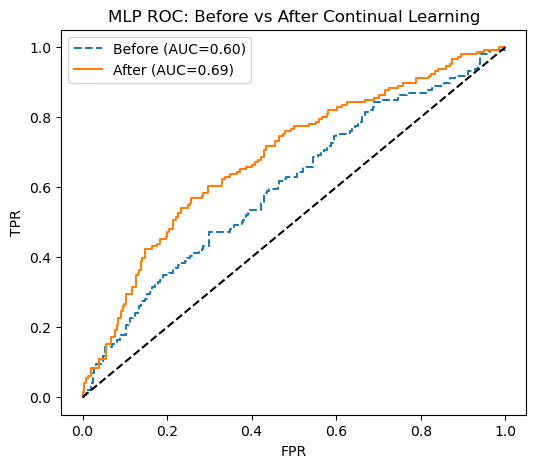

In [312]:
from sklearn.neural_network import MLPClassifier

mlp_base = MLPClassifier(hidden_layer_sizes=(8,),
                         max_iter=500,
                         random_state=42)

mlp_base.fit(X_d1_train_sc, y_d1_train)

y_pred_before = mlp_base.predict(X_d2_test_sc)
y_prob_before = mlp_base.predict_proba(X_d2_test_sc)[:,1]

mlp_cl = MLPClassifier(hidden_layer_sizes=(8,),
                       max_iter=500,
                       warm_start=True,
                       random_state=42)

mlp_cl.fit(X_d1_train_sc, y_d1_train)
mlp_cl.fit(X_d2_train_sc, y_d2_train)

y_pred_after = mlp_cl.predict(X_d2_test_sc)
y_prob_after = mlp_cl.predict_proba(X_d2_test_sc)[:,1]

mlp_before, fpr_b, tpr_b = get_metrics(y_d2_test, y_pred_before, y_prob_before)
mlp_after,  fpr_a, tpr_a = get_metrics(y_d2_test, y_pred_after, y_prob_after)

print("=== MLP BEFORE ===", mlp_before)
print("=== MLP AFTER  ===", mlp_after)

plt.figure(figsize=(6,5))
plt.plot(fpr_b, tpr_b, '--', label=f'Before (AUC={mlp_before["AUC"]:.2f})')
plt.plot(fpr_a, tpr_a, label=f'After (AUC={mlp_after["AUC"]:.2f})')
plt.plot([0,1],[0,1],'k--')

plt.xlabel("FPR")
plt.ylabel("TPR")
plt.title("MLP ROC: Before vs After Continual Learning")
plt.legend()
plt.show()

In [313]:
historical.to_csv('historical_data.csv', index=False)
current.to_csv('current_data.csv', index=False)